# 02 · ML Model Training — Real Estate Investment Advisor
### Phase 3: classification, regression and MLflow tracking

**Notebook:** `02_ML_Model_Training.ipynb`  **Runs in:** local Jupyter Notebook / JupyterLab (Python 3.10–3.12)  
**Inputs:** the files written by Phase 2 (`outputs/engineered_features.csv`, `feature_dictionary.csv`, `notebook_checks.csv`, `data_quality_report.csv`, `cleaning_log.csv`, `cleaned_housing_data.csv`).  
**Does not:** build the Streamlit app (that is the next phase).

---

## What this notebook does
1. Loads the Phase 2 files and verifies them.
2. **Splits the data first** (80% train / 20% test).
3. **Only then** constructs the two targets:
   - a **5-year price scenario** (`Future_Price_5Y_Lakhs`) using an *assumed* 8% annual growth;
   - a rule-based **Good Investment** label whose thresholds are fitted on the **training rows only**.
4. Builds leak-free preprocessing pipelines.
5. Trains and compares baselines and models for both tasks, with cross-validation on the training set and a single evaluation on the test set.
6. Tracks every run in **MLflow** and registers the chosen model for each task.
7. Saves pipelines and metadata that the Streamlit phase will load.

## Why the results may be disappointing — and why that is fine
Phase 2 showed that **no available feature visibly explains price** (every column's η² was at chance level), that **neither target exists in the data**, and that the data behaves like randomly generated data. So we *expect* honest models to land close to the baselines. The notebook is built so that the **truth shows up in the numbers**: it reports baselines next to every model, adds two clearly labelled "leakage demonstration" experiments, and prints automatic verdicts instead of hand-written conclusions.

## How to run
Run the cells **in order** (Kernel → Restart & Run All). A full run trains about 20 models; if your computer is slow, set `QUICK_RUN = True` in the configuration cell to use a 15% sample first (numbers will differ from a full run). See `PHASE3_RUN_GUIDE.md` for setup details.

## 1. Decision log

Seven decisions were agreed for this phase. The table shows exactly where each one is implemented. A few extra design choices follow it.

| # | Decision | How this notebook implements it |
|---|---|---|
| 1 | **8% growth is an assumption**, not a forecast | `GROWTH_RATE = 0.08`; `Future_Price_5Y_Lakhs = Price_in_Lakhs × 1.08⁵`. Named, tagged in MLflow and worded everywhere as an *assumed scenario*. A sensitivity table (5% / 8% / 10%) is shown in Section 5. |
| 2 | **Good Investment is a documented rule**, fitted on **training data only** | Section 5.2. Value test (price per sq ft at or below the **training** median of the property's City × Property_Type segment) **and** a quality score of at least 3 out of 5. Thresholds are saved to `label_rule.json` and applied unchanged to the test set. It is a *rule-based label*, **not proof of profitability**. |
| 3 | **`Price_in_Lakhs` is excluded from regression inputs** | Because the target is `Price × constant`, using price as input would be target leakage. Guard assertions in Section 6. A separate, clearly labelled *formula-recovery* experiment demonstrates the leak. |
| 4 | **Invalid `Floor_No` / `Total_Floors` records are flagged and handled consistently** | The 116,304 rows with `Floor_No > Total_Floors` are **kept** (they cannot be repaired) and flagged by `flag_floor_gt_total`. Both floor columns are excluded from **every** model's inputs. Section 13.3 reports test performance separately for flagged and unflagged rows. |
| 5 | **`Locality` only if cardinality and generalisation are handled** | 500 levels is far too many for one-hot encoding. Section 10 tests `Locality` with **cross-fitted target encoding** (the encoder never sees the rows it encodes) and adopts it **only** if a pre-declared cross-validation gain is reached. |
| 6 | **`Infra_Score` treatment documented** | Kept exactly as defined in Phase 2 (unweighted `Nearby_Schools + Nearby_Hospitals + Transport_Level`, range 2–22) **for description only**. It is **not a model input**; its components are used instead so models can learn their own weights. Section 6.3 gives the reasons and training-set evidence. |
| 7 | **No claims about real returns or verified future prices** | Wording rules in Section 16.2; every saved model carries a disclaimer in `model_metadata.json`. |

**Additional design choices**
- **Split:** 80/20, `random_state = 42`, stratified by `City`; the label does not exist yet at split time, so it cannot be stratified on.
- **Model selection** uses **3-fold cross-validation on the training set only**. The test set is used to *report*, never to choose.
- **Baselines first:** predict-the-prior (classification) and predict-the-mean (regression).
- **Skill thresholds, declared before seeing any result:** a model counts as showing skill only if CV ROC AUC ≥ 0.52 (classification) or CV R² ≥ 0.01 (regression). These are judgement values you may change in the configuration cell.
- **Imbalance:** the "Good Investment" class is the minority (about a quarter of rows), handled with class weights; accuracy alone is not trusted.
- **No hyper-parameter search:** with almost no signal, tuning would only fit noise. Fixed, moderate settings keep models small and comparable.
- **Deviations from the Phase 2 feature dictionary:** `Amenity_Count` is dropped because it is exactly the sum of the five amenity flags (redundant), and `Public_Transport_Accessibility` is encoded inside the pipeline instead of using the pre-made `Transport_Level` column. Both are documented, neither changes information content.

## 2. Setup

In [1]:
import os, sys, json, time, platform, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance

try:
    from sklearn.preprocessing import TargetEncoder        # needs scikit-learn >= 1.3
except ImportError as err:
    raise ImportError("scikit-learn >= 1.4 is required (see requirements.txt).") from err

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from mlflow.models import infer_signature

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)   # the do-nothing baseline predicts no positives
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)

print("Python      :", sys.version.split()[0], "|", platform.system())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("mlflow      :", mlflow.__version__)
print("xgboost     :", __import__("xgboost").__version__ if HAS_XGB else "NOT INSTALLED -> HistGradientBoosting will be used instead")

Python      : 3.14.2 | Windows
pandas      : 3.1.0
numpy       : 2.5.4
scikit-learn: 1.8.0
mlflow      : 3.17.2
xgboost     : 3.4.1


### PATCH 3 — environment guard (insert right after the Section 2 cell that prints the library versions)
The notebook, the saved models and the Streamlit app must all run in **one** Python environment. If the notebook's kernel is a different interpreter from the one where `pip install -r requirements.txt` was run (the usual cause of "xgboost is listed but not available" and of a scikit-learn 1.7.2 vs 1.8.0 mismatch), this cell stops early and prints the exact fix instead of silently training with a fallback model.

In [2]:
# PATCH 3 - environment guard
import sys

REQUIRED_SKLEARN = "1.8.0"       # same exact pin as requirements.txt
STRICT_ENVIRONMENT = True        # True = stop with instructions when the environment is wrong; False = print a warning only

print("Python interpreter used by THIS notebook kernel:", sys.executable)
print("scikit-learn:", sklearn.__version__, "| xgboost:", __import__("xgboost").__version__ if HAS_XGB else "NOT importable in this kernel")

problems = []
if sklearn.__version__ != REQUIRED_SKLEARN:
    problems.append(f"scikit-learn is {sklearn.__version__} in this kernel, but requirements.txt pins {REQUIRED_SKLEARN}. "
                    "Models saved here could not be loaded safely by an app running a different version.")
if not HAS_XGB:
    problems.append("xgboost cannot be imported in this kernel, so a HistGradientBoosting fallback would be used instead of XGBoost.")

if problems:
    message = ("ENVIRONMENT PROBLEM:\n- " + "\n- ".join(problems) +
               "\n\nFix: in a terminal with the project's virtual environment ACTIVE run\n"
               "    python -m pip install -r requirements-dev.txt\n"
               "    python -m ipykernel install --user --name reia --display-name \"Python (reia)\"\n"
               "then in Jupyter choose Kernel -> Change kernel -> 'Python (reia)', restart, and run the notebook again.\n"
               "(Set STRICT_ENVIRONMENT = False only if you knowingly accept the fallback.)")
    if STRICT_ENVIRONMENT:
        raise RuntimeError(message)
    print("WARNING:", message)
else:
    print("PASS: scikit-learn matches the pin and xgboost is available in this kernel.")

Python interpreter used by THIS notebook kernel: C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Scripts\python.exe
scikit-learn: 1.8.0 | xgboost: 3.4.1
PASS: scikit-learn matches the pin and xgboost is available in this kernel.


### 2.1 Configuration
Everything you might want to change is in this one cell. **Do not change the random seed or the split settings between runs** if you want comparable results.

In [3]:
# ---- Reproducibility and split ----
SEED = 42
TEST_SIZE = 0.20

# ---- Target definitions ----
GROWTH_RATE = 0.08            # ASSUMED annual growth (decision 1). A scenario, NOT a forecast.
HORIZON_YEARS = 5
GROWTH_MULTIPLIER = (1 + GROWTH_RATE) ** HORIZON_YEARS
QUALITY_THRESHOLD = 3         # label rule: at least 3 of 5 quality criteria (decision 2)

# ---- Evaluation ----
CV_FOLDS = 3
MIN_AUC_ABOVE_CHANCE = 0.02   # classification "shows skill" if CV ROC AUC >= 0.5 + this
MIN_R2 = 0.01                 # regression "shows skill" if CV R2 >= this
MIN_LOCALITY_AUC_GAIN = 0.01  # adopt Locality (classification) only if CV AUC gain >= this in the mean AND every fold
MIN_LOCALITY_R2_GAIN = 0.005  # same for regression R2

# ---- Speed switch ----
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"   # set to True here for a fast 15% trial run
QUICK_FRAC = 0.15
if QUICK_RUN:
    print("QUICK_RUN is ON: using a", int(QUICK_FRAC * 100), "% sample. Do not report these numbers as final.")

# ---- Folders (all relative to the folder that contains this notebook) ----
PROJECT_ROOT = Path.cwd()
OUTPUTS_DIR = PROJECT_ROOT / "outputs"              # Phase 2 results (read only)
PHASE3_DIR = PROJECT_ROOT / "phase3_outputs"        # tables, figures, label rule, split ids
FIG_DIR = PHASE3_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"                # saved pipelines + metadata
MLFLOW_DIR = PROJECT_ROOT / "mlflow"                # MLflow database and artifacts
for d in (PHASE3_DIR, FIG_DIR, MODELS_DIR, MLFLOW_DIR):
    d.mkdir(parents=True, exist_ok=True)

SESSION = time.strftime("%Y%m%d-%H%M%S")            # tags every run created by this execution
print("Project folder:", PROJECT_ROOT)
print("Session id    :", SESSION)
print(f"Growth multiplier ({GROWTH_RATE:.0%} for {HORIZON_YEARS} years): {GROWTH_MULTIPLIER:.6f}")

def save_fig(fig, name):
    fig.tight_layout()
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=110, bbox_inches="tight")
    return path

Project folder: C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor
Session id    : 20261029-091223
Growth multiplier (8% for 5 years): 1.469328


## 3. Load and verify the Phase 2 outputs
We read the Phase 2 files, confirm that they are what Phase 2 promised, and only then continue. Nothing here modifies them.

In [4]:
required = ["engineered_features.csv", "cleaned_housing_data.csv", "feature_dictionary.csv",
            "notebook_checks.csv", "data_quality_report.csv", "cleaning_log.csv"]
missing_files = [f for f in required if not (OUTPUTS_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing in {OUTPUTS_DIR}: {missing_files}. Put this notebook in the same folder as the Phase 2 'outputs' "
        "folder (or copy that folder next to it), then run again."
    )
print("All required Phase 2 files found in", OUTPUTS_DIR)

df_all = pd.read_csv(OUTPUTS_DIR / "engineered_features.csv")
print("engineered_features.csv:", df_all.shape)

All required Phase 2 files found in C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\outputs
engineered_features.csv: (250000, 36)


In [5]:
EXPECTED_COLUMNS = [
    "ID", "State", "City", "Locality", "Property_Type", "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Year_Built", "Furnished_Status", "Floor_No", "Total_Floors", "Age_of_Property", "Nearby_Schools",
    "Nearby_Hospitals", "Public_Transport_Accessibility", "Parking_Space", "Security", "Amenities", "Facing",
    "Owner_Type", "Availability_Status", "Price_per_SqFt_exact", "flag_floor_gt_total", "flag_stored_ppsf_zero",
    "Price_per_SqFt_INR", "Has_Clubhouse", "Has_Garden", "Has_Gym", "Has_Playground", "Has_Pool", "Amenity_Count",
    "Transport_Level", "Infra_Score", "Size_per_BHK",
]
assert list(df_all.columns) == EXPECTED_COLUMNS, "Column names differ from the Phase 2 export."
assert df_all.shape == (250_000, 36), f"Unexpected shape {df_all.shape}"
assert df_all.isna().sum().sum() == 0, "Unexpected missing values"
assert df_all["ID"].is_unique, "Duplicate IDs"
assert not any(c in df_all.columns for c in ["Good_Investment", "Future_Price_5Y", "Future_Price"]), \
    "A target column already exists in the Phase 2 export - it should not."
print("PASS: 250,000 x 36, same column names as Phase 2, no missing values, unique IDs, no target columns present.")

# The saved cleaned file should equal the original 23 columns of the engineered file
df_cleaned = pd.read_csv(OUTPUTS_DIR / "cleaned_housing_data.csv")
same = df_cleaned[EXPECTED_COLUMNS[:23]].equals(df_all[EXPECTED_COLUMNS[:23]])
print("PASS" if same else "WARNING", "- original 23 columns identical in cleaned_housing_data.csv and engineered_features.csv")
print("Flagged impossible-floor rows:", int(df_all["flag_floor_gt_total"].sum()), "(Phase 2 reported 116,304)")
del df_cleaned

PASS: 250,000 x 36, same column names as Phase 2, no missing values, unique IDs, no target columns present.
PASS - original 23 columns identical in cleaned_housing_data.csv and engineered_features.csv
Flagged impossible-floor rows: 116304 (Phase 2 reported 116,304)


In [6]:
phase2_checks = pd.read_csv(OUTPUTS_DIR / "notebook_checks.csv")
print("Phase 2 notebook checks:", phase2_checks["status"].value_counts().to_dict())
flags = phase2_checks[phase2_checks["status"] == "FLAG"]
print("\nThe known Phase 2 FLAG (Phase 1 said every locality is in all 42 cities; the data says 499 of 500):")
display(flags[["check", "detail"]])
if len(flags) > 1 or (len(flags) == 1 and "localit" not in flags.iloc[0]["check"].lower()):
    print("WARNING: your Phase 2 run has different FLAGs than expected - investigate before trusting Phase 3.")

print("\nData-quality report (Phase 2):")
display(pd.read_csv(OUTPUTS_DIR / "data_quality_report.csv"))
print("Cleaning log (Phase 2):")
display(pd.read_csv(OUTPUTS_DIR / "cleaning_log.csv"))
feature_dictionary = pd.read_csv(OUTPUTS_DIR / "feature_dictionary.csv")

Phase 2 notebook checks: {'PASS': 25, 'FLAG': 1}

The known Phase 2 FLAG (Phase 1 said every locality is in all 42 cities; the data says 499 of 500):


,check,detail
20,All 500 localities occur in all 42 cities (Phase 1 statement),499 of 500 do; Locality_117 appears in only 41 cities



Data-quality report (Phase 2):


,issue,rows_affected,pct_of_rows,proposed_treatment
0,Floor_No > Total_Floors (logically impossible),116304,46.52,KEEP rows; add flag column; exclude Floor_No/Total_Floors from model features (cannot be repaired)
1,Houses/Villas with Floor_No > 0,161644,64.66,KEEP; floor columns not trusted for non-apartments
2,Stored Price_per_SqFt rounded to 2 decimals (only 100 distinct values),250000,100.00,KEEP original; create exact Price_per_SqFt_exact = Price/Size and use that for analysis
3,Stored Price_per_SqFt equals 0 (rounding artifact),2534,1.01,KEEP; replaced by exact ratio; flag column added
4,"Stored Price_per_SqFt differs from round(Price/Size, 2)",21,0.01,KEEP; negligible (rounding ties)
5,Under_Construction properties with a past Year_Built (all have Year_Built <= 2023),125035,50.01,KEEP; do not use Availability_Status together with Age as if both were reliable; document
6,Under 200 sqft per BHK (implausibly cramped),10080,4.03,KEEP; threshold is a judgement call; size_per_bhk derived for EDA only
7,IQR outliers in stored Price_per_SqFt (all on the high side),20020,8.01,KEEP; they come from dividing by small sizes; analyse on a log scale; do not cap or delete
8,IQR outliers in exact Price/Size,19723,7.89,KEEP; same reason


Cleaning log (Phase 2):


,step,action,rows_changed
0,5.1,Stripped leading/trailing spaces in all text columns,0
1,5.2,No missing values found - no imputation needed,0
2,5.3,No duplicate rows found - nothing dropped,0
3,5.4,"Checked category spellings - no duplicates in spelling, no renaming required",0
4,5.5,Added Price_per_SqFt_exact (original column kept),250000
5,5.5,Added flag_floor_gt_total,116304
6,5.5,Added flag_stored_ppsf_zero,2534
7,5.6,"Investigated price/sqft outliers - kept all rows (they are arithmetic results of small sizes, not errors)",0


## 4. Train/test split — before any target is built
The split happens **first**. Everything that is *learned from data* (segment medians for the label, encoders, scalers) will use the **training rows only**.

We stratify by `City` so both sets contain every city in similar proportions.

In [7]:
df = df_all.sample(frac=QUICK_FRAC, random_state=SEED).reset_index(drop=True) if QUICK_RUN else df_all.copy()

train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=SEED, stratify=df["City"])
df_train = df.loc[train_idx].reset_index(drop=True)
df_test = df.loc[test_idx].reset_index(drop=True)

assert set(df_train["ID"]).isdisjoint(set(df_test["ID"])), "ID overlap between train and test!"
assert len(df_train) + len(df_test) == len(df)

city_share = pd.DataFrame({"train_%": df_train["City"].value_counts(normalize=True) * 100,
                           "test_%": df_test["City"].value_counts(normalize=True) * 100})
print(f"Train rows: {len(df_train):,} | Test rows: {len(df_test):,}")
print(f"Largest gap in a city's share between train and test: {(city_share['train_%'] - city_share['test_%']).abs().max():.3f} percentage points")
print("Cities in test but not in train:", sorted(set(df_test["City"]) - set(df_train["City"])))

split_ids = pd.concat([pd.DataFrame({"ID": df_train["ID"], "set": "train"}), pd.DataFrame({"ID": df_test["ID"], "set": "test"})])
split_ids.to_csv(PHASE3_DIR / "split_ids.csv", index=False)
SPLIT_FINGERPRINT = hashlib.sha256(",".join(map(str, sorted(df_train["ID"]))).encode()).hexdigest()[:16]
print("Saved split_ids.csv | train-ID fingerprint:", SPLIT_FINGERPRINT)

Train rows: 200,000 | Test rows: 50,000
Largest gap in a city's share between train and test: 0.001 percentage points
Cities in test but not in train: []
Saved split_ids.csv | train-ID fingerprint: 726c8219006a6c3a


## 5. Target construction (after the split)

### 5.1 Regression target — an *assumed* five-year price scenario
The data contains no price history, so a five-year price can only be a **projection**:

`Future_Price_5Y_Lakhs = Price_in_Lakhs × (1 + 0.08)⁵ = Price_in_Lakhs × 1.469328`

> **Read this carefully.** The 8% rate is an **assumption we chose**, not something measured from the data and not a forecast of the market. Because every property is multiplied by the same constant, this target is *today's price in disguise*. A model of it can only learn how today's price relates to the features — which, as Phase 2 showed, is hardly at all. A fixed multiplier needs no training to compute; the model's job here is only to estimate it from property characteristics.

This formula uses no learned statistic, so the order of split and construction cannot leak anything; we still build it after the split as agreed.

In [8]:
TARGET_REG = "Future_Price_5Y_Lakhs"
y_train_reg = df_train["Price_in_Lakhs"] * GROWTH_MULTIPLIER
y_test_reg = df_test["Price_in_Lakhs"] * GROWTH_MULTIPLIER
y_train_reg.name = y_test_reg.name = TARGET_REG

print(f"Training target: mean {y_train_reg.mean():.2f}, std {y_train_reg.std():.2f}, min {y_train_reg.min():.2f}, max {y_train_reg.max():.2f} lakhs")

sens = pd.DataFrame({"assumed_annual_growth": [0.05, 0.08, 0.10]})
sens["5yr_multiplier"] = (1 + sens["assumed_annual_growth"]) ** HORIZON_YEARS
sens["median_train_scenario_price_lakhs"] = df_train["Price_in_Lakhs"].median() * sens["5yr_multiplier"]
print("\nSensitivity of the scenario to the assumed growth rate (illustration - the models use 8% only):")
display(sens.round(3))

Training target: mean 374.25, std 207.69, min 14.69, max 734.66 lakhs

Sensitivity of the scenario to the assumed growth rate (illustration - the models use 8% only):


,assumed_annual_growth,5yr_multiplier,median_train_scenario_price_lakhs
0,0.05,1.276,324.431
1,0.08,1.469,373.503
2,0.10,1.611,409.392


### 5.2 Classification target — the rule-based "Good Investment" label
There is no return or appreciation column, so "good investment" can only be a **rule we write**. This label means:

> *"The property is cheaper per sq ft than similar properties **and** has at least 3 of 5 desirable features."*

It does **not** say the property will appreciate or earn a return, and it is **not proof of profitability**.

**The rule**
- **Value test:** `Price_per_SqFt_exact` ≤ the **training-set median** of the property's `City × Property_Type` segment (126 segments). If a segment were missing from the training data, the training-set overall median is used.
- **Quality score** (one point each): `BHK ≥ 3`, `Availability_Status == Ready_to_Move`, `Parking_Space == Yes`, `Security == Yes`, `Public_Transport_Accessibility == High`.
- **Good_Investment = 1** if the value test is passed **and** the quality score ≥ `QUALITY_THRESHOLD` (3).

The medians are calculated by `fit_label_rule(df_train)` — a function that **only receives the training rows** — and the saved rule is applied unchanged to the test rows.

In [9]:
def fit_label_rule(train_frame):
    """Learn the rule's thresholds from TRAINING rows only."""
    seg = train_frame.groupby(["City", "Property_Type"])["Price_per_SqFt_exact"].median()
    return {
        "rule_version": "v1",
        "description": "Good_Investment = (price per sqft <= training median of its City x Property_Type segment) AND (quality score >= threshold)",
        "fitted_on_rows": int(len(train_frame)),
        "quality_threshold": QUALITY_THRESHOLD,
        "quality_criteria": ["BHK >= 3", "Availability_Status == Ready_to_Move", "Parking_Space == Yes",
                             "Security == Yes", "Public_Transport_Accessibility == High"],
        "global_median_ppsf_lakhs": float(train_frame["Price_per_SqFt_exact"].median()),
        "segment_median_ppsf_lakhs": {f"{c}|{t}": float(v) for (c, t), v in seg.items()},
        "disclaimer": "Rule-based label. Not an observed outcome and not proof of profitability.",
    }

def quality_score(frame):
    return ((frame["BHK"] >= 3).astype(int)
            + (frame["Availability_Status"] == "Ready_to_Move").astype(int)
            + (frame["Parking_Space"] == "Yes").astype(int)
            + (frame["Security"] == "Yes").astype(int)
            + (frame["Public_Transport_Accessibility"] == "High").astype(int))

def apply_label_rule(frame, rule):
    keys = frame["City"] + "|" + frame["Property_Type"]
    medians = keys.map(rule["segment_median_ppsf_lakhs"]).fillna(rule["global_median_ppsf_lakhs"])
    value_ok = frame["Price_per_SqFt_exact"] <= medians
    return (value_ok & (quality_score(frame) >= rule["quality_threshold"])).astype(int)

LABEL_RULE = fit_label_rule(df_train)                 # <- training rows only
assert LABEL_RULE["fitted_on_rows"] == len(df_train)
TARGET_CLS = "Good_Investment"
y_train_cls = apply_label_rule(df_train, LABEL_RULE); y_train_cls.name = TARGET_CLS
y_test_cls = apply_label_rule(df_test, LABEL_RULE);   y_test_cls.name = TARGET_CLS

with open(PHASE3_DIR / "label_rule.json", "w") as f:
    json.dump(LABEL_RULE, f, indent=2)

prevalence = pd.DataFrame({
    "rows": [len(df_train), len(df_test)],
    "good_investment_rows": [int(y_train_cls.sum()), int(y_test_cls.sum())],
    "share_good_%": [100 * y_train_cls.mean(), 100 * y_test_cls.mean()],
}, index=["train", "test"])
display(prevalence.round(2))
print("Segments with a training median:", len(LABEL_RULE["segment_median_ppsf_lakhs"]))
print("Quality-score distribution in TRAIN (% of rows):")
print((quality_score(df_train).value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print("\nSaved label_rule.json")

,rows,good_investment_rows,share_good_%
train,200000,47711,23.86
test,50000,11771,23.54


Segments with a training median: 126
Quality-score distribution in TRAIN (% of rows):
0     3.31
1    16.70
2    32.40
3    30.93
4    14.06
5     2.59

Saved label_rule.json


**Reading the table:** the minority class ("good") is roughly a quarter of the rows, in both train and test, which is why the evaluation later uses F1, precision, recall and ROC AUC rather than accuracy alone. Remember also: because the label is *defined* by price, size, BHK, status, parking, security and transport, a model that is allowed to see those columns would simply re-learn the rule (Section 11.3 demonstrates this).

## 6. Feature sets and leakage guards

### 6.1 Column groups
| Group | Columns | Why |
|---|---|---|
| **Label-defining** | `Price_in_Lakhs`, `Price_per_SqFt*`, `Size_in_SqFt`, `BHK`, `Availability_Status`, `Parking_Space`, `Security`, `Public_Transport_Accessibility` (and anything built from them: `Transport_Level`, `Infra_Score`, `Size_per_BHK`) | They define the Good Investment label |
| **Price-derived** | `Price_in_Lakhs`, `Price_per_SqFt`, `Price_per_SqFt_exact`, `Price_per_SqFt_INR` | They contain the regression target |
| **Excluded always** | `ID`, `State` (redundant with `City`), `Year_Built` (redundant with `Age_of_Property`), `Floor_No`, `Total_Floors` (contradictory), `Amenities` (replaced by flags), `Amenity_Count` (sum of flags), `Infra_Score`, `Size_per_BHK`, `flag_*` | See Phase 2 feature dictionary |
| **Tested separately** | `Locality` | Section 10 |

Three **feature sets** result:
- **Classification — primary (honest):** no label-defining columns.
- **Regression — primary (honest):** no price-derived columns.
- **Leakage demonstrations:** classification with *all* label inputs ("rule recovery"), regression with `Price_in_Lakhs` ("formula recovery"). These are labelled and never used as the project's models.

In [10]:
AMENITY_FLAGS = ["Has_Clubhouse", "Has_Garden", "Has_Gym", "Has_Playground", "Has_Pool"]
GEO_AND_TYPE = ["City", "Property_Type", "Furnished_Status", "Owner_Type", "Facing"]
GENERAL_NUMERIC = ["Age_of_Property", "Nearby_Schools", "Nearby_Hospitals"]

LABEL_DEFINING = ["Price_in_Lakhs", "Price_per_SqFt", "Price_per_SqFt_exact", "Price_per_SqFt_INR", "Size_in_SqFt", "BHK",
                  "Availability_Status", "Parking_Space", "Security", "Public_Transport_Accessibility",
                  "Transport_Level", "Infra_Score", "Size_per_BHK"]
PRICE_DERIVED = ["Price_in_Lakhs", "Price_per_SqFt", "Price_per_SqFt_exact", "Price_per_SqFt_INR"]
NEVER_INPUTS = ["ID", "State", "Year_Built", "Floor_No", "Total_Floors", "Amenities", "Amenity_Count",
                "Infra_Score", "Size_per_BHK", "flag_floor_gt_total", "flag_stored_ppsf_zero",
                "Transport_Level", "Price_per_SqFt", "Price_per_SqFt_exact", "Price_per_SqFt_INR"]

# Classification: nothing that defines the label
CLS_FEATURES = GENERAL_NUMERIC + AMENITY_FLAGS + GEO_AND_TYPE
# Regression: everything legitimate about the property except price-derived columns
REG_FEATURES = (["Size_in_SqFt", "BHK"] + GENERAL_NUMERIC + AMENITY_FLAGS + GEO_AND_TYPE
                + ["Parking_Space", "Security", "Availability_Status", "Public_Transport_Accessibility"])
# Leakage demonstrations
CLS_RULE_RECOVERY_FEATURES = (CLS_FEATURES + ["Size_in_SqFt", "BHK", "Availability_Status", "Parking_Space", "Security",
                                              "Public_Transport_Accessibility", "Price_in_Lakhs", "Price_per_SqFt_exact"])
REG_FORMULA_RECOVERY_FEATURES = REG_FEATURES + ["Price_in_Lakhs"]

# ---- guards: the notebook stops if a leak sneaks in ----
assert set(CLS_FEATURES).isdisjoint(LABEL_DEFINING), "Label-defining column in the honest classification features!"
assert set(REG_FEATURES).isdisjoint(PRICE_DERIVED), "Price-derived column in the honest regression features!"
assert set(CLS_FEATURES + REG_FEATURES).isdisjoint(["Floor_No", "Total_Floors", "Infra_Score", "Amenity_Count", "State", "Year_Built"])
assert all(c in df.columns for c in set(CLS_RULE_RECOVERY_FEATURES + REG_FORMULA_RECOVERY_FEATURES))
print("PASS: leakage guards - honest classification inputs contain no label-defining column;",
      "honest regression inputs contain no price-derived column; floor columns are excluded everywhere.")
print(f"\nClassification inputs ({len(CLS_FEATURES)}):", CLS_FEATURES)
print(f"\nRegression inputs ({len(REG_FEATURES)}):", REG_FEATURES)

PASS: leakage guards - honest classification inputs contain no label-defining column; honest regression inputs contain no price-derived column; floor columns are excluded everywhere.

Classification inputs (13): ['Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground', 'Has_Pool', 'City', 'Property_Type', 'Furnished_Status', 'Owner_Type', 'Facing']

Regression inputs (19): ['Size_in_SqFt', 'BHK', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground', 'Has_Pool', 'City', 'Property_Type', 'Furnished_Status', 'Owner_Type', 'Facing', 'Parking_Space', 'Security', 'Availability_Status', 'Public_Transport_Accessibility']


### 6.2 Invalid floor records (decision 4)
`Floor_No > Total_Floors` is logically impossible and cannot be repaired. We therefore (a) **keep the rows** (deleting nearly half the data would be unjustified), (b) **flag** them (`flag_floor_gt_total`, created in Phase 2), and (c) **exclude both floor columns from every model**, so a wrong floor number can never influence a prediction. Section 13.3 checks that performance is the same on flagged and unflagged test rows.

In [11]:
floor_flag = pd.DataFrame({
    "rows": [len(df_train), len(df_test)],
    "impossible_floor_rows": [int(df_train["flag_floor_gt_total"].sum()), int(df_test["flag_floor_gt_total"].sum())],
    "share_%": [100 * df_train["flag_floor_gt_total"].mean(), 100 * df_test["flag_floor_gt_total"].mean()],
}, index=["train", "test"])
display(floor_flag.round(2))

,rows,impossible_floor_rows,share_%
train,200000,93126,46.56
test,50000,23178,46.36


### 6.3 `Infra_Score` treatment and weighting (decision 6)
- **Definition (unchanged from Phase 2):** `Infra_Score = Nearby_Schools + Nearby_Hospitals + Transport_Level` with `Transport_Level` = 0/1/2 for Low/Medium/High. Weights are equal per unit, so schools and hospitals (1–10 each) count far more than transport (0–2). That weighting is **our own convention**, not evidence-based.
- **Treatment:** **not a model input.** Reasons: (1) it is an exact linear combination of three columns the models already receive, so it adds no information; (2) it includes transport, which is part of the label rule, so it would leak into classification; (3) fixing weights ourselves would be arbitrary — models learn their own weights from the components.
- **Where it is still used:** EDA and later app visuals only.
- **Evidence (training rows only):** the rank correlations below show whether the score relates to the targets at all.

In [12]:
from scipy import stats
rows = []
for col in ["Infra_Score", "Nearby_Schools", "Nearby_Hospitals", "Transport_Level"]:
    rho_reg = stats.spearmanr(df_train[col], y_train_reg)[0]
    rho_cls = stats.spearmanr(df_train[col], y_train_cls)[0]
    rows.append({"column": col, "spearman_with_future_price": rho_reg, "spearman_with_good_investment": rho_cls})
display(pd.DataFrame(rows).set_index("column").round(4))
print("Correlations near 0 mean the composite adds nothing the components lack. Transport_Level correlates with the label",
      "partly by construction (it is one of the five quality criteria).")

,spearman_with_future_price,spearman_with_good_investment
column,,
Infra_Score,-0.0015,0.0373
Nearby_Schools,0.0004,0.0005
Nearby_Hospitals,-0.0026,0.0027
Transport_Level,-0.0005,0.1854


Correlations near 0 mean the composite adds nothing the components lack. Transport_Level correlates with the label partly by construction (it is one of the five quality criteria).


## 7. Preprocessing pipelines

A **pipeline** bundles preprocessing and the model so that *every* step is learned from the training rows only (inside cross-validation, only from the training part of each fold) and applied unchanged to unseen rows.

| Column type | Treatment |
|---|---|
| Numeric (`Size_in_SqFt`, `BHK`, `Age_of_Property`, `Nearby_*`, amenity flags, and price columns in the demos) | `StandardScaler` (needed for linear models, harmless for trees) |
| Nominal categories (`City`, `Property_Type`, `Furnished_Status`, `Owner_Type`, `Facing`) | One-hot encoding; unseen categories are ignored |
| Yes/No columns (`Parking_Space`, `Security`, `Availability_Status`) | 0/1 ordinal with a fixed order |
| `Public_Transport_Accessibility` | Ordinal Low < Medium < High → 0/1/2 |
| `Locality` (only if adopted) | **Cross-fitted target encoding** with smoothing: each row is encoded using only *other* rows, and rare localities are shrunk toward the overall average |

There were no missing values in Phase 2, so no imputer is needed (the pipeline raises an error rather than hiding a problem if one ever appears).

In [13]:
NUMERIC_COLS = (["Size_in_SqFt", "BHK", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals"] + AMENITY_FLAGS
                + ["Price_in_Lakhs", "Price_per_SqFt_exact"])
CATEGORICAL_COLS = ["City", "Property_Type", "Furnished_Status", "Owner_Type", "Facing"]
BINARY_ORDER = {"Parking_Space": ["No", "Yes"], "Security": ["No", "Yes"],
                "Availability_Status": ["Under_Construction", "Ready_to_Move"]}
ORDINAL_ORDER = {"Public_Transport_Accessibility": ["Low", "Medium", "High"]}

def build_preprocessor(features, task):
    """Build the ColumnTransformer for a list of input columns. task = 'classification' or 'regression'."""
    num = [c for c in features if c in NUMERIC_COLS]
    cat = [c for c in features if c in CATEGORICAL_COLS]
    binary = [c for c in features if c in BINARY_ORDER]
    ordinal = [c for c in features if c in ORDINAL_ORDER]
    use_locality = "Locality" in features
    unknown = set(features) - set(num + cat + binary + ordinal + (["Locality"] if use_locality else []))
    assert not unknown, f"No preprocessing rule for: {unknown}"

    parts = []
    if num:
        parts.append(("num", StandardScaler(), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    if binary:
        parts.append(("bin", OrdinalEncoder(categories=[BINARY_ORDER[c] for c in binary]), binary))
    if ordinal:
        parts.append(("ord", OrdinalEncoder(categories=[ORDINAL_ORDER[c] for c in ordinal]), ordinal))
    if use_locality:
        te = TargetEncoder(target_type="binary" if task == "classification" else "continuous",
                           smooth="auto", cv=5, shuffle=True, random_state=SEED)
        parts.append(("locality", te, ["Locality"]))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)

# Show what the transformed matrix looks like for the honest regression feature set
demo_prep = build_preprocessor(REG_FEATURES, "regression").fit(df_train[REG_FEATURES])
names = demo_prep.get_feature_names_out()
print(f"{len(REG_FEATURES)} input columns -> {len(names)} model features after encoding")
print(list(names[:12]), "...")
del demo_prep

19 input columns -> 69 model features after encoding
['Size_in_SqFt', 'BHK', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground', 'Has_Pool', 'City_Ahmedabad', 'City_Amritsar'] ...


## 8. MLflow setup

MLflow records, for every run: parameters, cross-validation and test metrics, tags, figures and the fitted pipeline. We use a **SQLite database** (`mlflow/mlflow.db`) because the **model registry** needs a database; artifacts go to `mlflow/artifacts/`.

Each execution of this notebook tags its runs with a `notebook_session` id, so repeated runs do not get mixed up in the summary tables. To start completely fresh, close the notebook and delete the `mlflow/` folder.

In [14]:
TRACKING_URI = "sqlite:///" + (MLFLOW_DIR / "mlflow.db").resolve().as_posix()
mlflow.set_tracking_uri(TRACKING_URI)
EXP_CLS = "RealEstate_GoodInvestment_Classification"
EXP_REG = "RealEstate_Future5Y_Regression"

def ensure_experiment(name):
    client = MlflowClient()
    if client.get_experiment_by_name(name) is None:
        client.create_experiment(name, artifact_location=(MLFLOW_DIR / "artifacts" / name).resolve().as_uri())
    mlflow.set_experiment(name)

ensure_experiment(EXP_CLS)
ensure_experiment(EXP_REG)
print("MLflow tracking URI:", TRACKING_URI)
print("Experiments ready:", EXP_CLS, "|", EXP_REG)

MLflow tracking URI: sqlite:///C:/Users/Nandini/Desktop/Prime/Real-Estate-Investment-Advisor/mlflow/mlflow.db
Experiments ready: RealEstate_GoodInvestment_Classification | RealEstate_Future5Y_Regression


## 9. Evaluation and logging helpers

**Classification metrics** (positive class = "Good Investment"): accuracy, balanced accuracy, precision, recall, F1, ROC AUC and PR AUC, plus the confusion matrix.  
**Regression metrics:** RMSE, MAE and R² (in lakhs of the assumed 8% scenario price), plus RMSE as a fraction of the target's standard deviation (a "predict the mean" model scores about 1.0).

Each `run_*` function (1) cross-validates on the **training set**, (2) fits on the full training set, (3) evaluates **once** on the test set, (4) logs everything to MLflow.

In [15]:
import re

def slug(text):
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_").lower()

def cls_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }

def reg_metrics(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return {"rmse": rmse, "mae": mean_absolute_error(y_true, y_pred), "r2": r2_score(y_true, y_pred),
            "rmse_over_target_std": rmse / float(np.std(y_true))}

def plot_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(4.8, 4))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title, fontsize=10)
    return fig

def common_tags(experiment_type, feature_set, estimator_name, task):
    tags = {"notebook_session": SESSION, "experiment_type": experiment_type, "feature_set": feature_set,
            "model_name": estimator_name, "split_seed": str(SEED), "split_fingerprint": SPLIT_FINGERPRINT,
            "quick_run": str(QUICK_RUN), "dataset": "outputs/engineered_features.csv (Phase 2)",
            "disclaimer": "Targets are constructed from assumptions; not real returns or verified future prices"}
    if task == "classification":
        tags.update({"target_definition": "rule-based label: value vs training segment median AND quality score >= %d" % QUALITY_THRESHOLD,
                     "label_rule_version": LABEL_RULE["rule_version"]})
    else:
        tags.update({"target_definition": "Price_in_Lakhs * (1+%.2f)^%d (ASSUMED growth scenario)" % (GROWTH_RATE, HORIZON_YEARS),
                     "growth_rate_assumed": str(GROWTH_RATE)})
    return tags

def log_sklearn_model(pipe, signature):
    """MLflow 3.x uses name=, MLflow 2.x uses artifact_path=; try both."""
    try:
        return mlflow.sklearn.log_model(pipe, name="model", signature=signature)
    except TypeError:
        return mlflow.sklearn.log_model(pipe, artifact_path="model", signature=signature)

CLS_SCORING = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}
REG_SCORING = {"neg_rmse": "neg_root_mean_squared_error", "neg_mae": "neg_mean_absolute_error", "r2": "r2"}
CLS_CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
REG_CV = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

CLS_RESULTS, REG_RESULTS, PIPES = [], [], {}
print("Helpers ready.")

Helpers ready.


### PATCH 1 — safe MLflow model logging (insert right after the Section 9 helper cell)
Newer MLflow versions save scikit-learn models in the pickle-free **skops** format, which refuses types it has not been told to trust (for example `sklearn.tree._tree.Tree` inside random forests). This cell re-defines `log_sklearn_model` so that it:
1. asks skops which types the fitted pipeline contains, and **prints and records them for review**;
2. passes only types that start with an explicit allowlist (`sklearn.`, `numpy.`, `xgboost.`) via MLflow's documented `skops_trusted_types` argument — anything else is **refused**, never auto-trusted;
3. **never raises**: if saving fails, the run is tagged `model_logging_failed`, a warning is printed, and training/evaluation of the other models carries on (`model_uri` is `None` for that run);
4. optionally (off by default) falls back to pickle-style saving if you set `FALLBACK_TO_PICKLE = True`.

In [16]:
# PATCH 1 - safe MLflow model logging (skops format with a reviewed allowlist of trusted types)
import types, inspect

ALLOWED_SKOPS_PREFIXES = ("sklearn.", "numpy.", "xgboost.")   # extend ONLY after reading the printed type list
FALLBACK_TO_PICKLE = False   # True = accept pickle-style model files if skops fails (only ever load models you created yourself)
SKOPS_REVIEW, _SEEN_TYPES = [], set()

def _supports_skops():
    """True if this MLflow version can save scikit-learn models in the skops format."""
    params = inspect.signature(mlflow.sklearn.log_model).parameters
    return "skops_trusted_types" in params or hasattr(mlflow.sklearn, "SERIALIZATION_FORMAT_SKOPS")

def _review_skops_types(pipe):
    """Ask skops which types this pipeline needs trusted; split them into approved / rejected."""
    import skops.io as sio
    untrusted = sorted(sio.get_untrusted_types(data=sio.dumps(pipe)))
    approved = [t for t in untrusted if t.startswith(ALLOWED_SKOPS_PREFIXES)]
    rejected = [t for t in untrusted if t not in approved]
    return approved, rejected

def _call_log_model(pipe, signature, **extra):
    try:                                                   # MLflow 3.x argument name
        return mlflow.sklearn.log_model(pipe, name="model", signature=signature, **extra)
    except TypeError:                                      # MLflow 2.x argument name
        return mlflow.sklearn.log_model(pipe, artifact_path="model", signature=signature, **extra)

def log_sklearn_model(pipe, signature):
    """Log a fitted pipeline to the ACTIVE run. Never raises; returns an object with .model_uri (None on failure)."""
    failed = types.SimpleNamespace(model_uri=None)
    try:
        if _supports_skops():
            approved, rejected = _review_skops_types(pipe)
            SKOPS_REVIEW.append({"run_id": mlflow.active_run().info.run_id, "approved": approved, "rejected": rejected})
            (PHASE3_DIR / "skops_types_review.json").write_text(json.dumps(SKOPS_REVIEW, indent=2))
            new_types = [t for t in approved if t not in _SEEN_TYPES]
            if new_types:
                print("   skops: newly approved types (allowlist prefixes", ALLOWED_SKOPS_PREFIXES, "):", new_types)
                _SEEN_TYPES.update(new_types)
            if rejected:
                raise RuntimeError(f"types outside the allowlist were NOT trusted: {rejected}")
            return _call_log_model(pipe, signature, serialization_format="skops", skops_trusted_types=approved)
        return _call_log_model(pipe, signature)            # older MLflow without skops support: its own default
    except Exception as err:
        msg = f"{type(err).__name__}: {str(err)[:300]}"
        print("   WARNING: model NOT saved to MLflow for this run ->", msg)
        mlflow.set_tags({"model_logging_failed": "True", "model_logging_error": msg[:500]})
        if FALLBACK_TO_PICKLE:
            try:
                info = _call_log_model(pipe, signature, serialization_format="cloudpickle")
                mlflow.set_tag("model_serialization_fallback", "cloudpickle")
                print("   fallback: saved with cloudpickle (pickle-style; load only models you created yourself)")
                return info
            except Exception as err2:
                print("   WARNING: pickle fallback also failed ->", f"{type(err2).__name__}: {str(err2)[:200]}")
        return failed

print("Patched log_sklearn_model is active. FALLBACK_TO_PICKLE =", FALLBACK_TO_PICKLE)

Patched log_sklearn_model is active. FALLBACK_TO_PICKLE = False


In [17]:
def run_classification(run_name, estimator, features, experiment_type, feature_set, store=True, log_model=True):
    while mlflow.active_run() is not None:      # a run left open by an interrupted cell would block start_run
        mlflow.end_run()
    ensure_experiment(EXP_CLS)
    X_tr, X_te = df_train[features], df_test[features]
    pipe = Pipeline([("prep", build_preprocessor(features, "classification")), ("model", estimator)])

    t0 = time.time()
    cv = cross_validate(pipe, X_tr, y_train_cls, cv=CLS_CV, scoring=CLS_SCORING)
    pipe.fit(X_tr, y_train_cls)
    fit_seconds = time.time() - t0

    proba = pipe.predict_proba(X_te)[:, 1]
    pred = pipe.predict(X_te)
    test = cls_metrics(y_test_cls, pred, proba)
    cm = confusion_matrix(y_test_cls, pred, labels=[0, 1])

    row = {"run_name": run_name, "experiment_type": experiment_type, "feature_set": feature_set,
           "model": type(estimator).__name__, "n_features_in": len(features)}
    for k in CLS_SCORING:
        row[f"cv_{k}_mean"] = float(np.mean(cv[f"test_{k}"])); row[f"cv_{k}_std"] = float(np.std(cv[f"test_{k}"]))
    row.update({f"test_{k}": v for k, v in test.items()})
    row.update({"fit_seconds": fit_seconds, "cm": cm, "cv_raw": cv})

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags(common_tags(experiment_type, feature_set, run_name, "classification"))
        mlflow.log_params({"n_input_features": len(features), "cv_folds": CV_FOLDS, "train_rows": len(df_train),
                           "test_rows": len(df_test), "train_positive_share": round(float(y_train_cls.mean()), 4),
                           **{f"model__{k}": str(v)[:250] for k, v in estimator.get_params().items()}})
        mlflow.log_metrics({**{f"cv_{k}_mean": row[f"cv_{k}_mean"] for k in CLS_SCORING},
                            **{f"cv_{k}_std": row[f"cv_{k}_std"] for k in CLS_SCORING},
                            **{f"test_{k}": v for k, v in test.items()}, "fit_seconds": fit_seconds})
        fig = plot_confusion(cm, f"{run_name}\n(test set, threshold 0.5)")
        cm_path = save_fig(fig, "cm_" + slug(run_name)); plt.close(fig)
        mlflow.log_artifact(str(cm_path), artifact_path="figures")
        feat_path = PHASE3_DIR / f"features_{slug(run_name)}.json"
        feat_path.write_text(json.dumps({"input_columns": features}, indent=2))
        mlflow.log_artifact(str(feat_path), artifact_path="features")
        if log_model:
            sig = infer_signature(X_te.head(200), pipe.predict(X_te.head(200)))
            info = log_sklearn_model(pipe, sig)
            row["model_uri"] = info.model_uri
        row["run_id"] = run.info.run_id

    if store:
        CLS_RESULTS.append(row); PIPES[("cls", run_name)] = pipe
    print(f"{run_name:<55s} CV AUC {row['cv_roc_auc_mean']:.4f} | test AUC {test['roc_auc']:.4f} | "
          f"F1 {test['f1']:.4f} | acc {test['accuracy']:.4f} | {fit_seconds:.0f}s")
    return row


def run_regression(run_name, estimator, features, experiment_type, feature_set, store=True, log_model=True):
    while mlflow.active_run() is not None:
        mlflow.end_run()
    ensure_experiment(EXP_REG)
    X_tr, X_te = df_train[features], df_test[features]
    pipe = Pipeline([("prep", build_preprocessor(features, "regression")), ("model", estimator)])

    t0 = time.time()
    cv = cross_validate(pipe, X_tr, y_train_reg, cv=REG_CV, scoring=REG_SCORING)
    pipe.fit(X_tr, y_train_reg)
    fit_seconds = time.time() - t0

    pred = pipe.predict(X_te)
    test = reg_metrics(y_test_reg, pred)

    row = {"run_name": run_name, "experiment_type": experiment_type, "feature_set": feature_set,
           "model": type(estimator).__name__, "n_features_in": len(features)}
    row["cv_rmse_mean"] = float(-np.mean(cv["test_neg_rmse"])); row["cv_rmse_std"] = float(np.std(cv["test_neg_rmse"]))
    row["cv_mae_mean"] = float(-np.mean(cv["test_neg_mae"]));   row["cv_mae_std"] = float(np.std(cv["test_neg_mae"]))
    row["cv_r2_mean"] = float(np.mean(cv["test_r2"]));          row["cv_r2_std"] = float(np.std(cv["test_r2"]))
    row.update({f"test_{k}": v for k, v in test.items()})
    row.update({"fit_seconds": fit_seconds, "cv_raw": cv})

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags(common_tags(experiment_type, feature_set, run_name, "regression"))
        mlflow.log_params({"n_input_features": len(features), "cv_folds": CV_FOLDS, "train_rows": len(df_train),
                           "test_rows": len(df_test), "growth_multiplier": round(GROWTH_MULTIPLIER, 6),
                           **{f"model__{k}": str(v)[:250] for k, v in estimator.get_params().items()}})
        mlflow.log_metrics({"cv_rmse_mean": row["cv_rmse_mean"], "cv_rmse_std": row["cv_rmse_std"],
                            "cv_mae_mean": row["cv_mae_mean"], "cv_r2_mean": row["cv_r2_mean"], "cv_r2_std": row["cv_r2_std"],
                            **{f"test_{k}": v for k, v in test.items()}, "fit_seconds": fit_seconds})
        feat_path = PHASE3_DIR / f"features_{slug(run_name)}.json"
        feat_path.write_text(json.dumps({"input_columns": features}, indent=2))
        mlflow.log_artifact(str(feat_path), artifact_path="features")
        if log_model:
            sig = infer_signature(X_te.head(200), pipe.predict(X_te.head(200)))
            info = log_sklearn_model(pipe, sig)
            row["model_uri"] = info.model_uri
        row["run_id"] = run.info.run_id

    if store:
        REG_RESULTS.append(row); PIPES[("reg", run_name)] = pipe
    print(f"{run_name:<55s} CV R2 {row['cv_r2_mean']:.4f} | test R2 {test['r2']:.4f} | "
          f"test RMSE {test['rmse']:.2f} | test MAE {test['mae']:.2f} | {fit_seconds:.0f}s")
    return row

print("run_classification() and run_regression() defined.")

run_classification() and run_regression() defined.


### 9.1 Model definitions
The same moderate settings are used everywhere so models are comparable. Random forests are kept small (`max_depth = 10`, `min_samples_leaf = 100`) so saved models stay light and cannot memorise noise. If `xgboost` is not installed, scikit-learn's `HistGradientBoosting` takes its place and the model name says so.

In [18]:
POS_WEIGHT = float((y_train_cls == 0).sum() / max((y_train_cls == 1).sum(), 1))   # negatives / positives, from TRAIN only

def make_classifiers():
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=100,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
                                          colsample_bytree=0.8, min_child_weight=50, tree_method="hist",
                                          eval_metric="logloss", scale_pos_weight=POS_WEIGHT, n_jobs=-1, random_state=SEED)
    else:
        models["HistGradientBoosting (XGBoost not installed)"] = HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.1, max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=SEED)
    return models

def make_regressors():
    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=100, n_jobs=-1, random_state=SEED),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
                                         colsample_bytree=0.8, min_child_weight=50, tree_method="hist",
                                         objective="reg:squarederror", n_jobs=-1, random_state=SEED)
    else:
        models["HistGradientBoosting (XGBoost not installed)"] = HistGradientBoostingRegressor(
            max_iter=200, learning_rate=0.1, max_depth=4, min_samples_leaf=100, random_state=SEED)
    return models

print("Classifiers:", list(make_classifiers()))
print("Regressors :", list(make_regressors()))
print(f"Class-imbalance ratio used for boosting weights (negatives/positives, train): {POS_WEIGHT:.3f}")

Classifiers: ['Logistic Regression', 'Random Forest', 'XGBoost']
Regressors : ['Linear Regression', 'Random Forest', 'XGBoost']
Class-imbalance ratio used for boosting weights (negatives/positives, train): 3.192


## 10. Decision 5 — is `Locality` worth using?
`Locality` has 500 levels, each repeated in every city and holding only about 500 rows (Phase 2). One-hot encoding it would add 500 columns and mostly memorise noise. We test it the safe way:

- **Cross-fitted target encoding** with smoothing (inside the pipeline, so it is learned from training folds only).
- A **fast, interpretable model** (logistic / linear regression) with and without `Locality`, on **identical cross-validation folds**.
- **Pre-declared rule:** adopt `Locality` only if the mean CV gain is at least the threshold set in the configuration **and** the gain is positive in **every** fold. Otherwise it stays out of all final models.

In [19]:
loc_rows = []

# --- classification ---
base = run_classification("LOCTEST cls: without Locality", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
                          CLS_FEATURES, "locality_test", "cls_primary", store=False, log_model=False)
withloc = run_classification("LOCTEST cls: with Locality (target-encoded)", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
                             CLS_FEATURES + ["Locality"], "locality_test", "cls_primary+Locality", store=False, log_model=False)
gain = np.array(withloc["cv_raw"]["test_roc_auc"]) - np.array(base["cv_raw"]["test_roc_auc"])
adopt_cls = bool(gain.mean() >= MIN_LOCALITY_AUC_GAIN and (gain > 0).all())
loc_rows.append({"task": "classification", "metric": "CV ROC AUC", "without": np.mean(base["cv_raw"]["test_roc_auc"]),
                 "with_locality": np.mean(withloc["cv_raw"]["test_roc_auc"]), "mean_gain": gain.mean(),
                 "fold_gains": np.round(gain, 4).tolist(), "required_gain": MIN_LOCALITY_AUC_GAIN, "adopted": adopt_cls})

# --- regression ---
base = run_regression("LOCTEST reg: without Locality", LinearRegression(), REG_FEATURES, "locality_test", "reg_primary", store=False, log_model=False)
withloc = run_regression("LOCTEST reg: with Locality (target-encoded)", LinearRegression(), REG_FEATURES + ["Locality"],
                         "locality_test", "reg_primary+Locality", store=False, log_model=False)
gain = np.array(withloc["cv_raw"]["test_r2"]) - np.array(base["cv_raw"]["test_r2"])
adopt_reg = bool(gain.mean() >= MIN_LOCALITY_R2_GAIN and (gain > 0).all())
loc_rows.append({"task": "regression", "metric": "CV R2", "without": np.mean(base["cv_raw"]["test_r2"]),
                 "with_locality": np.mean(withloc["cv_raw"]["test_r2"]), "mean_gain": gain.mean(),
                 "fold_gains": np.round(gain, 4).tolist(), "required_gain": MIN_LOCALITY_R2_GAIN, "adopted": adopt_reg})

locality_decision = pd.DataFrame(loc_rows)
display(locality_decision)
locality_decision.to_csv(PHASE3_DIR / "locality_decision.csv", index=False)

# Apply the decision to the feature sets used from here on
if adopt_cls:
    CLS_FEATURES = CLS_FEATURES + ["Locality"]
if adopt_reg:
    REG_FEATURES = REG_FEATURES + ["Locality"]
print("\nLocality adopted for classification:", adopt_cls, "| for regression:", adopt_reg)

LOCTEST cls: without Locality                           CV AUC 0.4981 | test AUC 0.5040 | F1 0.3163 | acc 0.5114 | 5s
LOCTEST cls: with Locality (target-encoded)             CV AUC 0.4980 | test AUC 0.5040 | F1 0.3162 | acc 0.5114 | 6s
LOCTEST reg: without Locality                           CV R2 -0.0005 | test R2 -0.0004 | test RMSE 207.73 | test MAE 179.84 | 8s
LOCTEST reg: with Locality (target-encoded)             CV R2 -0.0005 | test R2 -0.0004 | test RMSE 207.73 | test MAE 179.84 | 8s


,task,metric,without,with_locality,mean_gain,fold_gains,required_gain,adopted
0,classification,CV ROC AUC,0.498051,0.497965,-0.000086,"[-0.0003, 0.0, 0.0]",0.010,False
1,regression,CV R2,-0.000475,-0.000486,-0.000011,"[0.0, 0.0, -0.0]",0.005,False



Locality adopted for classification: False | for regression: False


In [20]:
for _, r in locality_decision.iterrows():
    verdict = "ADOPTED" if r["adopted"] else "REJECTED"
    print(f"{r['task'].capitalize():<15s} {r['metric']}: {r['without']:.4f} -> {r['with_locality']:.4f} "
          f"(mean gain {r['mean_gain']:+.4f}, required {r['required_gain']:+.4f}, folds {r['fold_gains']}) => Locality {verdict}")
print("\nA rejected Locality means: no measurable generalisation benefit, so it stays out of every final model.")

Classification  CV ROC AUC: 0.4981 -> 0.4980 (mean gain -0.0001, required +0.0100, folds [-0.0003, 0.0, 0.0]) => Locality REJECTED
Regression      CV R2: -0.0005 -> -0.0005 (mean gain -0.0000, required +0.0050, folds [0.0, 0.0, -0.0]) => Locality REJECTED

A rejected Locality means: no measurable generalisation benefit, so it stays out of every final model.


## 11. Classification — "Is this a Good Investment?" (rule-based label)

Three groups of runs, all evaluated on the same untouched test set:

| Group | Inputs | Purpose |
|---|---|---|
| **Baseline** | any (ignored) | "Predict the prior": what you get without learning anything. ROC AUC of exactly 0.5 means chance. |
| **Primary (honest)** | no label-defining columns | The models the project may report. |
| **Rule recovery (leakage demo)** | *all* label inputs, including price | Shows what happens when the label's own ingredients are given to the model: the model re-learns the rule. **Never reported as skill.** |

### 11.1 Baseline

In [21]:
run_classification("CLS baseline: Dummy (predict prior)", DummyClassifier(strategy="prior"),
                   CLS_FEATURES, "baseline", "cls_primary")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


CLS baseline: Dummy (predict prior)                     CV AUC 0.5000 | test AUC 0.5000 | F1 0.0000 | acc 0.7646 | 3s


{'run_name': 'CLS baseline: Dummy (predict prior)',
 'experiment_type': 'baseline',
 'feature_set': 'cls_primary',
 'model': 'DummyClassifier',
 'n_features_in': 13,
 'cv_roc_auc_mean': 0.5,
 'cv_roc_auc_std': 0.0,
 'cv_f1_mean': 0.0,
 'cv_f1_std': 0.0,
 'cv_accuracy_mean': 0.7614450000380724,
 'cv_accuracy_std': 5.38425615154947e-06,
 'cv_precision_mean': 0.0,
 'cv_precision_std': 0.0,
 'cv_recall_mean': 0.0,
 'cv_recall_std': 0.0,
 'test_accuracy': 0.76458,
 'test_balanced_accuracy': 0.5,
 'test_precision': 0.0,
 'test_recall': 0.0,
 'test_f1': 0.0,
 'test_roc_auc': 0.5,
 'test_pr_auc': 0.23542,
 'fit_seconds': 2.7285847663879395,
 'cm': array([[38229,     0],
        [11771,     0]]),
 'cv_raw': {'fit_time': array([0.41655707, 0.40939164, 0.40496302]),
  'score_time': array([0.30554676, 0.30374336, 0.29859853]),
  'test_roc_auc': array([0.5, 0.5, 0.5]),
  'test_f1': array([0., 0., 0.]),
  'test_accuracy': array([0.76144119, 0.76144119, 0.76145261]),
  'test_precision': array([0., 0.

### 11.2 Primary (honest) models
Logistic Regression, Random Forest and a gradient-boosting model (XGBoost if installed). Class weights compensate for the minority class. *This cell trains several models; allow a few minutes.*

In [22]:
for model_name, est in make_classifiers().items():
    run_classification(f"CLS primary: {model_name}", est, CLS_FEATURES, "primary", "cls_primary")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


CLS primary: Logistic Regression                        CV AUC 0.4981 | test AUC 0.5040 | F1 0.3163 | acc 0.5114 | 5s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


   skops: newly approved types (allowlist prefixes ('sklearn.', 'numpy.', 'xgboost.') ): ['sklearn.tree._tree.Tree']
CLS primary: Random Forest                              CV AUC 0.4973 | test AUC 0.5022 | F1 0.3050 | acc 0.5395 | 47s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


   skops: newly approved types (allowlist prefixes ('sklearn.', 'numpy.', 'xgboost.') ): ['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier']
CLS primary: XGBoost                                    CV AUC 0.4971 | test AUC 0.5036 | F1 0.3189 | acc 0.5158 | 14s


### 11.3 Leakage demonstration — rule recovery
Here the models receive `Price_in_Lakhs`, `Price_per_SqFt_exact`, `Size_in_SqFt`, `BHK`, `Availability_Status`, `Parking_Space`, `Security` and `Public_Transport_Accessibility` — exactly the ingredients of the label. A high score here proves **only that the model can re-learn our rule**, not that it can find good investments.

In [23]:
for model_name, est in make_classifiers().items():
    run_classification(f"CLS rule-recovery (LEAKY): {model_name}", est, CLS_RULE_RECOVERY_FEATURES,
                       "rule_recovery", "cls_rule_recovery")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


CLS rule-recovery (LEAKY): Logistic Regression          CV AUC 0.9645 | test AUC 0.9647 | F1 0.7966 | acc 0.8899 | 8s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


CLS rule-recovery (LEAKY): Random Forest                CV AUC 0.9979 | test AUC 0.9981 | F1 0.8350 | acc 0.9074 | 44s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


CLS rule-recovery (LEAKY): XGBoost                      CV AUC 0.9997 | test AUC 0.9997 | F1 0.9889 | acc 0.9948 | 21s


### 11.4 Classification comparison table

,run_name,experiment_type,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
0,CLS baseline: Dummy (predict prior),baseline,0.5000,0.0000,0.0000,0.7646,0.5000,0.0000,0.0000,0.0000,0.5000,0.2354
1,CLS primary: Logistic Regression,primary,0.4981,0.0011,0.3196,0.5114,0.5005,0.2358,0.4800,0.3163,0.5040,0.2384
2,CLS primary: Random Forest,primary,0.4973,0.0005,0.3040,0.5395,0.5014,0.2366,0.4293,0.3050,0.5022,0.2380
3,CLS primary: XGBoost,primary,0.4971,0.0016,0.3139,0.5158,0.5039,0.2384,0.4814,0.3189,0.5036,0.2393
4,CLS rule-recovery (LEAKY): Logistic Regression,rule_recovery,0.9645,0.0009,0.7993,0.8899,0.8988,0.7050,0.9156,0.7966,0.9647,0.8887
5,CLS rule-recovery (LEAKY): Random Forest,rule_recovery,0.9979,0.0003,0.8335,0.9074,0.9378,0.7192,0.9953,0.8350,0.9981,0.9948
6,CLS rule-recovery (LEAKY): XGBoost,rule_recovery,0.9997,0.0001,0.9886,0.9948,0.9951,0.9822,0.9958,0.9889,0.9997,0.9987


Test-set share of the positive class (a classifier that says 'good' for everyone has precision = 0.2354 )
Accuracy of always predicting 'not good': 0.7646


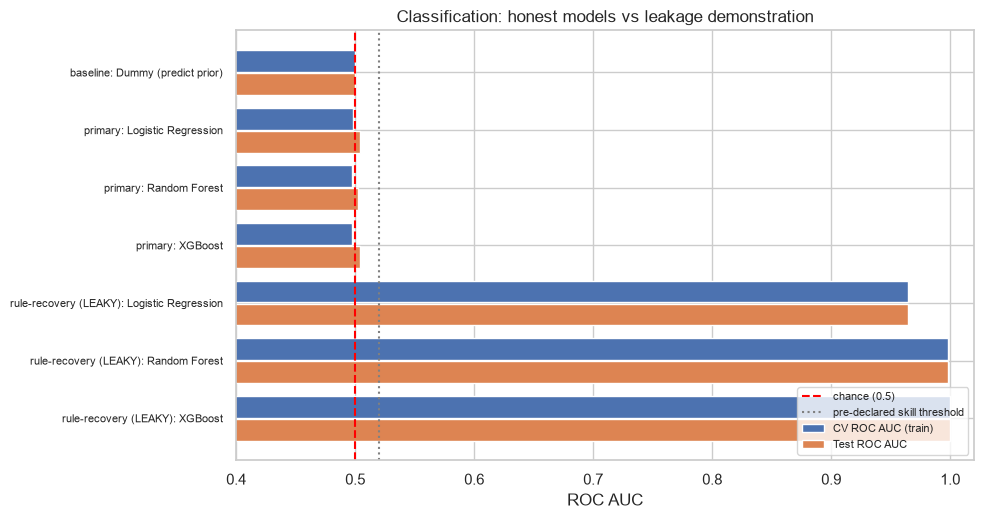

In [24]:
cls_cols = ["run_name", "experiment_type", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean",
            "test_accuracy", "test_balanced_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc"]
cls_table = pd.DataFrame(CLS_RESULTS)[cls_cols]
display(cls_table.round(4))
cls_table.to_csv(PHASE3_DIR / "classification_results.csv", index=False)
print("Test-set share of the positive class (a classifier that says 'good' for everyone has precision =", round(float(y_test_cls.mean()), 4), ")")
print("Accuracy of always predicting 'not good':", round(1 - float(y_test_cls.mean()), 4))

plot_df = cls_table.copy(); plot_df["label"] = plot_df["run_name"].str.replace("CLS ", "", regex=False)
fig, ax = plt.subplots(figsize=(10, 0.55 * len(plot_df) + 1.5))
ypos = np.arange(len(plot_df))
ax.barh(ypos - 0.2, plot_df["cv_roc_auc_mean"], height=0.38, label="CV ROC AUC (train)", color="#4C72B0")
ax.barh(ypos + 0.2, plot_df["test_roc_auc"], height=0.38, label="Test ROC AUC", color="#DD8452")
ax.axvline(0.5, color="red", linestyle="--", label="chance (0.5)")
ax.axvline(0.5 + MIN_AUC_ABOVE_CHANCE, color="grey", linestyle=":", label="pre-declared skill threshold")
ax.set_yticks(ypos); ax.set_yticklabels(plot_df["label"], fontsize=8); ax.invert_yaxis()
ax.set_xlim(0.4, 1.02); ax.set_xlabel("ROC AUC"); ax.set_title("Classification: honest models vs leakage demonstration"); ax.legend(fontsize=8, loc="lower right")
save_fig(fig, "cls_model_comparison"); plt.show()

### 11.5 Confusion matrices (test set, decision threshold 0.5) — baseline and honest models

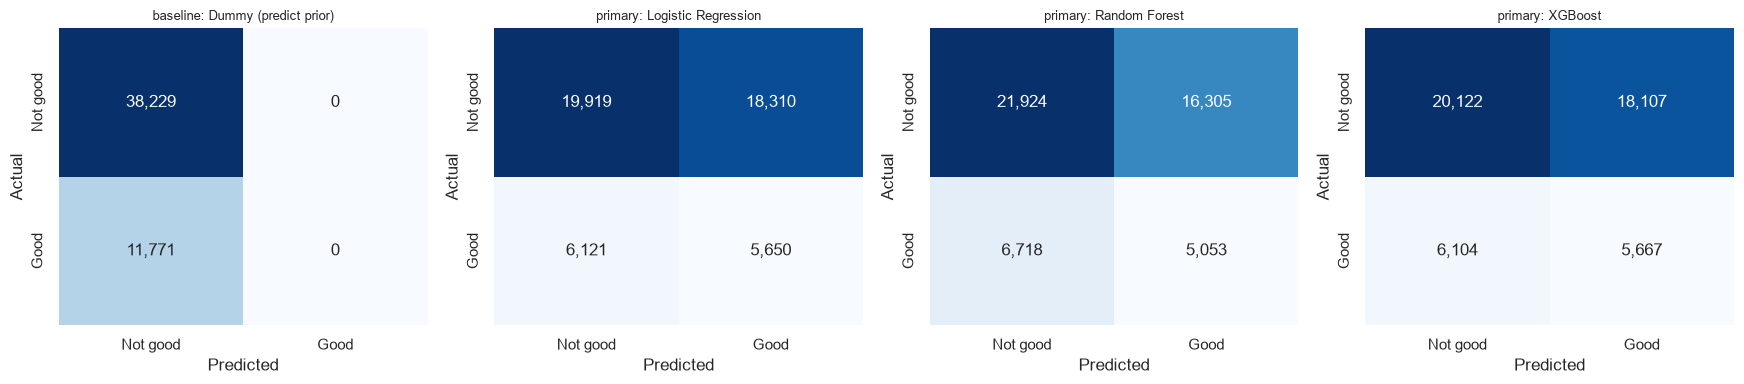

Rows = actual class, columns = predicted class. The bottom-right cell counts correctly identified 'Good' properties.


In [25]:
shown = [r for r in CLS_RESULTS if r["experiment_type"] in ("baseline", "primary")]
fig, axes = plt.subplots(1, len(shown), figsize=(4.4 * len(shown), 4))
axes = np.atleast_1d(axes)
for ax, r in zip(axes, shown):
    sns.heatmap(r["cm"], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_title(r["run_name"].replace("CLS ", ""), fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
save_fig(fig, "cls_confusion_matrices"); plt.show()
print("Rows = actual class, columns = predicted class. The bottom-right cell counts correctly identified 'Good' properties.")

In [26]:
cls_primary = [r for r in CLS_RESULTS if r["experiment_type"] == "primary"]
cls_base = [r for r in CLS_RESULTS if r["experiment_type"] == "baseline"][0]
cls_leaky = [r for r in CLS_RESULTS if r["experiment_type"] == "rule_recovery"]
best_honest = max(cls_primary, key=lambda r: r["cv_roc_auc_mean"])
best_leaky = max(cls_leaky, key=lambda r: r["test_roc_auc"])
print("AUTOMATIC READ-OUT (classification)")
print(f"- Baseline test ROC AUC: {cls_base['test_roc_auc']:.4f}; share of 'good' in test: {y_test_cls.mean():.3f}")
print(f"- Best honest model by CV AUC: {best_honest['run_name']}  (CV AUC {best_honest['cv_roc_auc_mean']:.4f}, test AUC {best_honest['test_roc_auc']:.4f}, test F1 {best_honest['test_f1']:.4f})")
if best_honest["cv_roc_auc_mean"] >= 0.5 + MIN_AUC_ABOVE_CHANCE:
    print(f"  -> meets the pre-declared skill threshold (CV AUC >= {0.5 + MIN_AUC_ABOVE_CHANCE:.2f}).")
else:
    print(f"  -> does NOT meet the pre-declared skill threshold (CV AUC >= {0.5 + MIN_AUC_ABOVE_CHANCE:.2f}): "
          "using the honest inputs, the models cannot rebuild the rule-based label any better than chance.")
print(f"- Leakage demo, best: {best_leaky['run_name']}  (test AUC {best_leaky['test_roc_auc']:.4f}, test F1 {best_leaky['test_f1']:.4f}).")
print("  A high score here only shows that the rule can be re-learned when its ingredients are visible.")

AUTOMATIC READ-OUT (classification)
- Baseline test ROC AUC: 0.5000; share of 'good' in test: 0.235
- Best honest model by CV AUC: CLS primary: Logistic Regression  (CV AUC 0.4981, test AUC 0.5040, test F1 0.3163)
  -> does NOT meet the pre-declared skill threshold (CV AUC >= 0.52): using the honest inputs, the models cannot rebuild the rule-based label any better than chance.
- Leakage demo, best: CLS rule-recovery (LEAKY): XGBoost  (test AUC 0.9997, test F1 0.9889).
  A high score here only shows that the rule can be re-learned when its ingredients are visible.


### PATCH 2 — class-imbalance review (insert right after the cell that prints "AUTOMATIC READ-OUT (classification)")
Only about a quarter of properties are labelled "good", so **accuracy is misleading**: a model that never says "good" scores about 76% accuracy and an F1 of exactly 0 (it makes no positive predictions, so precision and recall for the "good" class are 0 by definition — that is expected for a majority-class baseline, not a bug). The table below puts every model next to three **reference predictors** computed from the test labels only (no fitting): *always "not good"*, *always "good"* and *random guessing at the base rate*.

In [27]:
# PATCH 2 - class-imbalance review for the Good Investment classifier
n_test = len(y_test_cls); n_pos = int(y_test_cls.sum()); n_neg = n_test - n_pos
prev = n_pos / n_test

refs = [
    {"model": "REFERENCE: always 'not good' (majority class)", "accuracy": 1 - prev, "precision": 0.0, "recall": 0.0, "f1": 0.0,
     "roc_auc": 0.5, "pr_auc": prev, "predicted_good_rate": 0.0, "TN": n_neg, "FP": 0, "FN": n_pos, "TP": 0},
    {"model": "REFERENCE: always 'good'", "accuracy": prev, "precision": prev, "recall": 1.0, "f1": 2 * prev / (1 + prev),
     "roc_auc": 0.5, "pr_auc": prev, "predicted_good_rate": 1.0, "TN": 0, "FP": n_neg, "FN": 0, "TP": n_pos},
    {"model": "REFERENCE: random guess at the base rate (expected values)", "accuracy": prev ** 2 + (1 - prev) ** 2,
     "precision": prev, "recall": prev, "f1": prev, "roc_auc": 0.5, "pr_auc": prev, "predicted_good_rate": prev,
     "TN": np.nan, "FP": np.nan, "FN": np.nan, "TP": np.nan},
]
rows = []
for r in CLS_RESULTS:
    tn, fp, fn, tp = [int(v) for v in r["cm"].ravel()]
    rows.append({"model": r["run_name"], "accuracy": r["test_accuracy"], "precision": r["test_precision"], "recall": r["test_recall"],
                 "f1": r["test_f1"], "roc_auc": r["test_roc_auc"], "pr_auc": r["test_pr_auc"],
                 "predicted_good_rate": (tp + fp) / n_test, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
imbalance = pd.DataFrame(refs + rows)
imbalance["pr_auc_minus_base_rate"] = imbalance["pr_auc"] - prev
always_good_f1 = 2 * prev / (1 + prev)
imbalance["f1_beats_always_good"] = [None if m.startswith("REFERENCE") else bool(f > always_good_f1 + 1e-12)
                                     for m, f in zip(imbalance["model"], imbalance["f1"])]
display(imbalance.round(4))
imbalance.to_csv(PHASE3_DIR / "classification_imbalance_review.csv", index=False)

dummy = [r for r in CLS_RESULTS if r["experiment_type"] == "baseline"][0]
d_tn, d_fp, d_fn, d_tp = [int(v) for v in dummy["cm"].ravel()]
print(f"\nBase rate of 'good' in the test set: {prev:.4f} ({n_pos:,} of {n_test:,}).")
print(f"Majority-class baseline: accuracy {dummy['test_accuracy']:.4f}, F1 {dummy['test_f1']:.4f}; confusion matrix "
      f"TN={d_tn:,} FP={d_fp:,} FN={d_fn:,} TP={d_tp:,}.")
print("  -> TP = 0 and FP = 0: it never predicts 'good', so precision/recall/F1 for 'good' are 0 by definition.")
print(f"Reference points: ROC AUC chance = 0.5; PR AUC chance = base rate = {prev:.4f}; "
      f"F1 of 'always good' = {always_good_f1:.4f}; F1 of random guessing = {prev:.4f}.")

honest = [r for r in CLS_RESULTS if r["experiment_type"] == "primary"]
best_h = max(honest, key=lambda r: r["cv_roc_auc_mean"])
threshold = 0.5 + MIN_AUC_ABOVE_CHANCE
print("\nHonest models versus the references:")
for r in honest:
    print(f"- {r['run_name']}: ROC AUC {r['test_roc_auc']:.4f}, PR AUC {r['test_pr_auc']:.4f} (base rate {prev:.4f}), "
          f"F1 {r['test_f1']:.4f} (always-good {always_good_f1:.4f}), accuracy {r['test_accuracy']:.4f} (majority {1 - prev:.4f})")
if best_h["cv_roc_auc_mean"] >= threshold:
    print(f"\nBest honest model ({best_h['run_name']}) meets the pre-declared threshold (CV ROC AUC {best_h['cv_roc_auc_mean']:.4f} >= {threshold:.2f}).")
    print("That is the minimum bar only: it still describes a rule-based label, not real investment outcomes.")
else:
    print(f"\nNOT RELIABLE: the best honest model ({best_h['run_name']}) has CV ROC AUC {best_h['cv_roc_auc_mean']:.4f}, below the "
          f"pre-declared threshold of {threshold:.2f}. It must not be presented as able to identify 'Good Investment' properties.")
    print("Its accuracy and F1 should not be quoted without the reference rows above.")

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_good_rate,TN,FP,FN,TP,pr_auc_minus_base_rate,f1_beats_always_good
0,REFERENCE: always 'not good' (majority class),0.7646,0.0000,0.0000,0.0000,0.5000,0.2354,0.0000,38229.0,0.0,11771.0,0.0,0.0000,None
1,REFERENCE: always 'good',0.2354,0.2354,1.0000,0.3811,0.5000,0.2354,1.0000,0.0,38229.0,0.0,11771.0,0.0000,None
2,REFERENCE: random guess at the base rate (expected values),0.6400,0.2354,0.2354,0.2354,0.5000,0.2354,0.2354,NaN,NaN,NaN,NaN,0.0000,None
3,CLS baseline: Dummy (predict prior),0.7646,0.0000,0.0000,0.0000,0.5000,0.2354,0.0000,38229.0,0.0,11771.0,0.0,0.0000,False
4,CLS primary: Logistic Regression,0.5114,0.2358,0.4800,0.3163,0.5040,0.2384,0.4792,19919.0,18310.0,6121.0,5650.0,0.0030,False
5,CLS primary: Random Forest,0.5395,0.2366,0.4293,0.3050,0.5022,0.2380,0.4272,21924.0,16305.0,6718.0,5053.0,0.0025,False
6,CLS primary: XGBoost,0.5158,0.2384,0.4814,0.3189,0.5036,0.2393,0.4755,20122.0,18107.0,6104.0,5667.0,0.0038,False
7,CLS rule-recovery (LEAKY): Logistic Regression,0.8899,0.7050,0.9156,0.7966,0.9647,0.8887,0.3058,33718.0,4511.0,993.0,10778.0,0.6532,True
8,CLS rule-recovery (LEAKY): Random Forest,0.9074,0.7192,0.9953,0.8350,0.9981,0.9948,0.3258,33654.0,4575.0,55.0,11716.0,0.7593,True
9,CLS rule-recovery (LEAKY): XGBoost,0.9948,0.9822,0.9958,0.9889,0.9997,0.9987,0.2387,38017.0,212.0,50.0,11721.0,0.7633,True



Base rate of 'good' in the test set: 0.2354 (11,771 of 50,000).
Majority-class baseline: accuracy 0.7646, F1 0.0000; confusion matrix TN=38,229 FP=0 FN=11,771 TP=0.
  -> TP = 0 and FP = 0: it never predicts 'good', so precision/recall/F1 for 'good' are 0 by definition.
Reference points: ROC AUC chance = 0.5; PR AUC chance = base rate = 0.2354; F1 of 'always good' = 0.3811; F1 of random guessing = 0.2354.

Honest models versus the references:
- CLS primary: Logistic Regression: ROC AUC 0.5040, PR AUC 0.2384 (base rate 0.2354), F1 0.3163 (always-good 0.3811), accuracy 0.5114 (majority 0.7646)
- CLS primary: Random Forest: ROC AUC 0.5022, PR AUC 0.2380 (base rate 0.2354), F1 0.3050 (always-good 0.3811), accuracy 0.5395 (majority 0.7646)
- CLS primary: XGBoost: ROC AUC 0.5036, PR AUC 0.2393 (base rate 0.2354), F1 0.3189 (always-good 0.3811), accuracy 0.5158 (majority 0.7646)

NOT RELIABLE: the best honest model (CLS primary: Logistic Regression) has CV ROC AUC 0.4981, below the pre-declar

## 12. Regression — estimated price after 5 years (assumed 8% scenario)

**Remember what the target is:** `Price_in_Lakhs × 1.469328`. Predicting it well from property characteristics means predicting *today's price* well; the 8% scenario adds no information.

| Group | Inputs | Purpose |
|---|---|---|
| **Baseline** | any (ignored) | Predict the training mean. R² ≈ 0 by definition. |
| **Primary (honest)** | no price-derived columns | Models the project may report. |
| **Formula recovery (leakage demo)** | primary inputs **plus `Price_in_Lakhs`** | Shows that giving the model today's price makes the "forecast" trivial. **Never reported as skill.** |

### 12.1 Baseline

In [28]:
run_regression("REG baseline: Dummy (predict training mean)", DummyRegressor(strategy="mean"),
               REG_FEATURES, "baseline", "reg_primary")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


REG baseline: Dummy (predict training mean)             CV R2 -0.0000 | test R2 -0.0000 | test RMSE 207.69 | test MAE 179.83 | 4s


{'run_name': 'REG baseline: Dummy (predict training mean)',
 'experiment_type': 'baseline',
 'feature_set': 'reg_primary',
 'model': 'DummyRegressor',
 'n_features_in': 19,
 'cv_rmse_mean': 207.6890027805946,
 'cv_rmse_std': 0.12184257053599591,
 'cv_mae_mean': 179.92079133827374,
 'cv_mae_std': 0.04043605196038062,
 'cv_r2_mean': -1.4493294849223423e-05,
 'cv_r2_std': 1.0260734946033202e-05,
 'test_rmse': 207.69251853204227,
 'test_mae': 179.82811865972687,
 'test_r2': -1.7879901112571872e-05,
 'test_rmse_over_target_std': 1.0000089399105951,
 'fit_seconds': 3.9610273838043213,
 'cv_raw': {'fit_time': array([0.70703793, 0.73989248, 0.73926973]),
  'score_time': array([0.26288915, 0.25587702, 0.26285267]),
  'test_neg_rmse': array([-207.85331958, -207.65177109, -207.56191767]),
  'test_neg_mae': array([-179.97686253, -179.90248341, -179.88302808]),
  'test_r2': array([-6.55951808e-06, -7.93804409e-06, -2.89823224e-05])},
 'model_uri': 'models:/m-906f6054abaf4285be286a2e3b99cb04',
 'run

### 12.2 Primary (honest) models
*This cell trains several models; allow a few minutes.*

In [29]:
for model_name, est in make_regressors().items():
    run_regression(f"REG primary: {model_name}", est, REG_FEATURES, "primary", "reg_primary")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


REG primary: Linear Regression                          CV R2 -0.0005 | test R2 -0.0004 | test RMSE 207.73 | test MAE 179.84 | 8s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


REG primary: Random Forest                              CV R2 -0.0005 | test R2 -0.0003 | test RMSE 207.72 | test MAE 179.83 | 220s


C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


   skops: newly approved types (allowlist prefixes ('sklearn.', 'numpy.', 'xgboost.') ): ['xgboost.sklearn.XGBRegressor']
REG primary: XGBoost                                    CV R2 -0.0026 | test R2 -0.0023 | test RMSE 207.92 | test MAE 179.95 | 12s


### 12.3 Leakage demonstration — formula recovery
`Price_in_Lakhs` is added to the inputs. Because the target is exactly `1.469328 × Price_in_Lakhs`, a plain linear model will recover it almost perfectly. We also measure the slope the model learned for price: it should be about 1.469.

In [30]:
leak_run = run_regression("REG formula-recovery (LEAKY): Linear Regression", LinearRegression(),
                          REG_FORMULA_RECOVERY_FEATURES, "formula_recovery", "reg_formula_recovery")

leak_pipe = PIPES[("reg", "REG formula-recovery (LEAKY): Linear Regression")]
X_probe = df_test[REG_FORMULA_RECOVERY_FEATURES].copy()
before = leak_pipe.predict(X_probe)
X_probe["Price_in_Lakhs"] = X_probe["Price_in_Lakhs"] + 1.0
slope = float((leak_pipe.predict(X_probe) - before).mean())
print(f"\nLearned effect of +1 lakh in today's price on the 'future price': {slope:.4f}   (true multiplier {GROWTH_MULTIPLIER:.4f})")

C:\Users\Nandini\Desktop\Prime\Real-Estate-Investment-Advisor\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


REG formula-recovery (LEAKY): Linear Regression         CV R2 1.0000 | test R2 1.0000 | test RMSE 0.00 | test MAE 0.00 | 7s

Learned effect of +1 lakh in today's price on the 'future price': 1.4693   (true multiplier 1.4693)


### 12.4 Regression comparison table

,run_name,experiment_type,cv_r2_mean,cv_r2_std,cv_rmse_mean,test_rmse,test_mae,test_r2,test_rmse_over_target_std
0,REG baseline: Dummy (predict training mean),baseline,-0.0000,0.0000,207.6890,207.6925,179.8281,-0.0000,1.0000
1,REG primary: Linear Regression,primary,-0.0005,0.0001,207.7368,207.7296,179.8433,-0.0004,1.0002
2,REG primary: Random Forest,primary,-0.0005,0.0002,207.7385,207.7192,179.8296,-0.0003,1.0001
3,REG primary: XGBoost,primary,-0.0026,0.0004,207.9559,207.9245,179.9543,-0.0023,1.0011
4,REG formula-recovery (LEAKY): Linear Regression,formula_recovery,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000


Test target standard deviation: 207.69 lakhs. A model that always predicts the mean has RMSE close to this.
Equivalent in TODAY's price units: divide an error in lakhs by 1.4693.


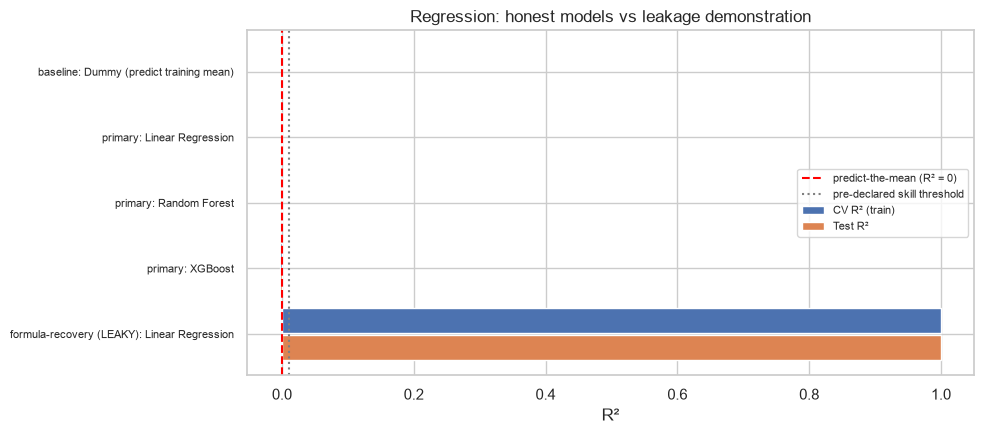

In [31]:
reg_cols = ["run_name", "experiment_type", "cv_r2_mean", "cv_r2_std", "cv_rmse_mean",
            "test_rmse", "test_mae", "test_r2", "test_rmse_over_target_std"]
reg_table = pd.DataFrame(REG_RESULTS)[reg_cols]
display(reg_table.round(4))
reg_table.to_csv(PHASE3_DIR / "regression_results.csv", index=False)
print(f"Test target standard deviation: {y_test_reg.std():.2f} lakhs. A model that always predicts the mean has RMSE close to this.")
print(f"Equivalent in TODAY's price units: divide an error in lakhs by {GROWTH_MULTIPLIER:.4f}.")

plot_df = reg_table.copy(); plot_df["label"] = plot_df["run_name"].str.replace("REG ", "", regex=False)
fig, ax = plt.subplots(figsize=(10, 0.6 * len(plot_df) + 1.5))
ypos = np.arange(len(plot_df))
ax.barh(ypos - 0.2, plot_df["cv_r2_mean"], height=0.38, label="CV R² (train)", color="#4C72B0")
ax.barh(ypos + 0.2, plot_df["test_r2"], height=0.38, label="Test R²", color="#DD8452")
ax.axvline(0, color="red", linestyle="--", label="predict-the-mean (R² = 0)")
ax.axvline(MIN_R2, color="grey", linestyle=":", label="pre-declared skill threshold")
ax.set_yticks(ypos); ax.set_yticklabels(plot_df["label"], fontsize=8); ax.invert_yaxis()
ax.set_xlabel("R²"); ax.set_title("Regression: honest models vs leakage demonstration"); ax.legend(fontsize=8, loc="center right")
save_fig(fig, "reg_model_comparison"); plt.show()

In [32]:
reg_primary = [r for r in REG_RESULTS if r["experiment_type"] == "primary"]
reg_base = [r for r in REG_RESULTS if r["experiment_type"] == "baseline"][0]
best_reg = max(reg_primary, key=lambda r: r["cv_r2_mean"])
print("AUTOMATIC READ-OUT (regression)")
print(f"- Baseline (predict the mean): test RMSE {reg_base['test_rmse']:.2f}, test R² {reg_base['test_r2']:.4f}")
print(f"- Best honest model by CV R²: {best_reg['run_name']}  (CV R² {best_reg['cv_r2_mean']:.4f}, test R² {best_reg['test_r2']:.4f}, "
      f"test RMSE {best_reg['test_rmse']:.2f}, test MAE {best_reg['test_mae']:.2f})")
if best_reg["cv_r2_mean"] >= MIN_R2:
    print(f"  -> meets the pre-declared skill threshold (CV R² >= {MIN_R2}).")
else:
    print(f"  -> does NOT meet the pre-declared skill threshold (CV R² >= {MIN_R2}): without today's price as an input, "
          "the honest models explain essentially none of the variation in the scenario price.")
leak = [r for r in REG_RESULTS if r["experiment_type"] == "formula_recovery"][0]
print(f"- Leakage demo: test R² {leak['test_r2']:.4f}, test RMSE {leak['test_rmse']:.4f} lakhs - a formula, not forecasting skill.")

AUTOMATIC READ-OUT (regression)
- Baseline (predict the mean): test RMSE 207.69, test R² -0.0000
- Best honest model by CV R²: REG primary: Linear Regression  (CV R² -0.0005, test R² -0.0004, test RMSE 207.73, test MAE 179.84)
  -> does NOT meet the pre-declared skill threshold (CV R² >= 0.01): without today's price as an input, the honest models explain essentially none of the variation in the scenario price.
- Leakage demo: test R² 1.0000, test RMSE 0.0000 lakhs - a formula, not forecasting skill.


## 13. Champions and deeper evaluation

### 13.1 Selecting the model for each task
**Rule (fixed in advance):** among the *honest primary* models, pick the best by **cross-validation on the training set** — highest ROC AUC for classification, highest R² for regression. The test set plays no part in the choice.

If the champion does not clear the pre-declared skill threshold, it is **still saved** (the app needs something to load) but its metadata says plainly that it does **not** beat the baseline in a meaningful way.

In [33]:
champ_cls = max([r for r in CLS_RESULTS if r["experiment_type"] == "primary"], key=lambda r: r["cv_roc_auc_mean"])
champ_reg = max([r for r in REG_RESULTS if r["experiment_type"] == "primary"], key=lambda r: r["cv_r2_mean"])
base_cls = [r for r in CLS_RESULTS if r["experiment_type"] == "baseline"][0]
base_reg = [r for r in REG_RESULTS if r["experiment_type"] == "baseline"][0]

skill_cls = bool(champ_cls["cv_roc_auc_mean"] >= 0.5 + MIN_AUC_ABOVE_CHANCE)
skill_reg = bool(champ_reg["cv_r2_mean"] >= MIN_R2)
pipe_cls = PIPES[("cls", champ_cls["run_name"])]
pipe_reg = PIPES[("reg", champ_reg["run_name"])]

print("CLASSIFICATION champion:", champ_cls["run_name"], "| CV AUC", round(champ_cls["cv_roc_auc_mean"], 4),
      "| meets skill threshold:", skill_cls)
print("REGRESSION champion    :", champ_reg["run_name"], "| CV R²", round(champ_reg["cv_r2_mean"], 4),
      "| meets skill threshold:", skill_reg)

CLASSIFICATION champion: CLS primary: Logistic Regression | CV AUC 0.4981 | meets skill threshold: False
REGRESSION champion    : REG primary: Linear Regression | CV R² -0.0005 | meets skill threshold: False


### 13.2 Uncertainty on the test set
A single test score is itself uncertain. We resample the test rows 200 times (bootstrap) to get a 95% interval for the champions and the baselines. If a champion's interval overlaps the baseline's, the difference is not trustworthy.

In [34]:
def bootstrap_ci(metric_fn, y_true, y_hat, n_boot=200):
    rng = np.random.RandomState(SEED)
    y_true, y_hat = np.asarray(y_true), np.asarray(y_hat)
    vals = []
    for _ in range(n_boot):
        i = rng.randint(0, len(y_true), len(y_true))
        vals.append(metric_fn(y_true[i], y_hat[i]))
    return np.percentile(vals, [2.5, 97.5])

proba_cls = pipe_cls.predict_proba(df_test[CLS_FEATURES])[:, 1]
pred_cls = pipe_cls.predict(df_test[CLS_FEATURES])
base_proba = PIPES[("cls", base_cls["run_name"])].predict_proba(df_test[CLS_FEATURES])[:, 1]
pred_reg = pipe_reg.predict(df_test[REG_FEATURES])
base_pred_reg = PIPES[("reg", base_reg["run_name"])].predict(df_test[REG_FEATURES])

rows = []
for label, proba in [("champion", proba_cls), ("baseline", base_proba)]:
    lo, hi = bootstrap_ci(roc_auc_score, y_test_cls, proba)
    rows.append({"task": "classification", "model": label, "metric": "ROC AUC", "value": roc_auc_score(y_test_cls, proba), "ci95_low": lo, "ci95_high": hi})
lo, hi = bootstrap_ci(f1_score, y_test_cls, pred_cls)
rows.append({"task": "classification", "model": "champion", "metric": "F1", "value": f1_score(y_test_cls, pred_cls), "ci95_low": lo, "ci95_high": hi})
for label, pr in [("champion", pred_reg), ("baseline", base_pred_reg)]:
    lo, hi = bootstrap_ci(r2_score, y_test_reg, pr)
    rows.append({"task": "regression", "model": label, "metric": "R²", "value": r2_score(y_test_reg, pr), "ci95_low": lo, "ci95_high": hi})
    rm = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
    lo, hi = bootstrap_ci(rm, y_test_reg, pr)
    rows.append({"task": "regression", "model": label, "metric": "RMSE (lakhs)", "value": rm(y_test_reg, pr), "ci95_low": lo, "ci95_high": hi})
uncertainty = pd.DataFrame(rows)
display(uncertainty.round(4))
uncertainty.to_csv(PHASE3_DIR / "test_uncertainty.csv", index=False)

,task,model,metric,value,ci95_low,ci95_high
0,classification,champion,ROC AUC,0.5040,0.4984,0.5095
1,classification,baseline,ROC AUC,0.5000,0.5000,0.5000
2,classification,champion,F1,0.3163,0.3109,0.3223
3,regression,champion,R²,-0.0004,-0.0007,-0.0000
4,regression,champion,RMSE (lakhs),207.7296,207.0541,208.4435
5,regression,baseline,R²,-0.0000,-0.0001,-0.0000
6,regression,baseline,RMSE (lakhs),207.6925,207.0027,208.4068


### 13.3 Flagged vs unflagged floor records (decision 4)
Floor columns are not model inputs, so predictions should be equally good on rows whose floor data is impossible and on rows where it is not. A large difference would signal a hidden problem.

In [35]:
rows = []
for flag_value, label in [(False, "consistent floors"), (True, "impossible floors (flagged)")]:
    mask = (df_test["flag_floor_gt_total"] == flag_value).values
    rows.append({"task": "classification", "slice": label, "rows": int(mask.sum()), "metric": "ROC AUC",
                 "value": roc_auc_score(y_test_cls[mask], proba_cls[mask])})
    rows.append({"task": "regression", "slice": label, "rows": int(mask.sum()), "metric": "R²",
                 "value": r2_score(y_test_reg[mask], pred_reg[mask])})
    rows.append({"task": "regression", "slice": label, "rows": int(mask.sum()), "metric": "RMSE (lakhs)",
                 "value": float(np.sqrt(mean_squared_error(y_test_reg[mask], pred_reg[mask])))})
floor_slices = pd.DataFrame(rows)
display(floor_slices.round(4))
floor_slices.to_csv(PHASE3_DIR / "floor_flag_slices.csv", index=False)

,task,slice,rows,metric,value
0,classification,consistent floors,26822,ROC AUC,0.4967
1,regression,consistent floors,26822,R²,-0.0003
2,regression,consistent floors,26822,RMSE (lakhs),207.4630
3,classification,impossible floors (flagged),23178,ROC AUC,0.5124
4,regression,impossible floors (flagged),23178,R²,-0.0005
5,regression,impossible floors (flagged),23178,RMSE (lakhs),208.0378


### 13.4 Diagnostics for the champions
**ROC curve and predicted probabilities** (classification) and **predicted vs actual** (regression). A model with real skill shows a curve clearly above the diagonal and points along the diagonal; a model without skill shows a curve on the diagonal and a horizontal cloud.

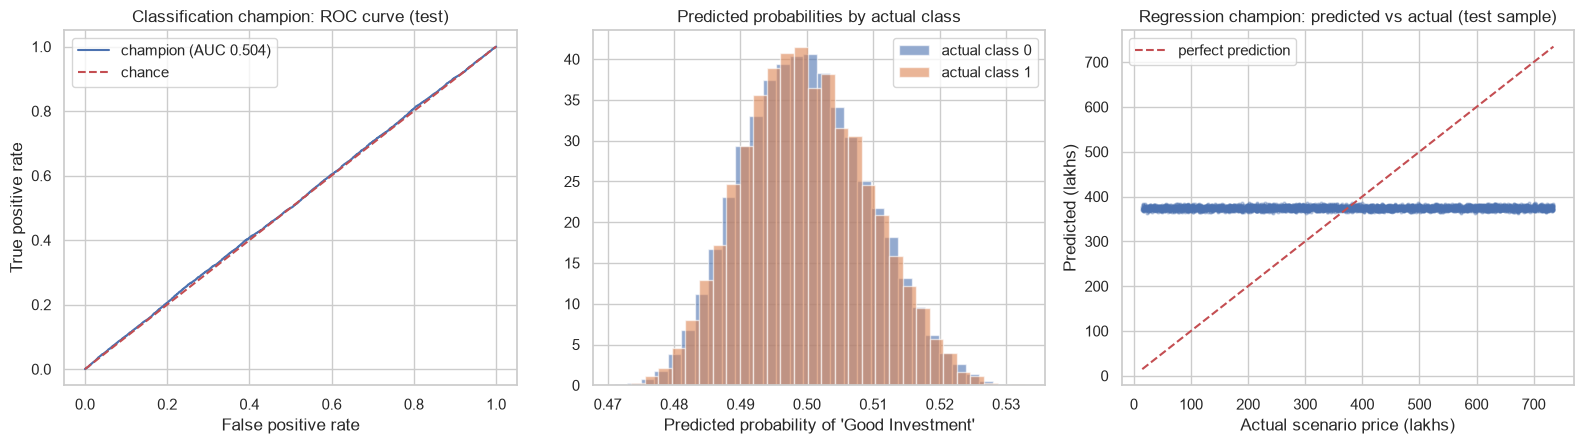

In [36]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
fpr, tpr, _ = roc_curve(y_test_cls, proba_cls)
axes[0].plot(fpr, tpr, label=f"champion (AUC {roc_auc_score(y_test_cls, proba_cls):.3f})")
axes[0].plot([0, 1], [0, 1], "r--", label="chance"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("Classification champion: ROC curve (test)"); axes[0].legend()

for cls_value, color in [(0, "#4C72B0"), (1, "#DD8452")]:
    axes[1].hist(proba_cls[(y_test_cls == cls_value).values], bins=30, alpha=0.6, color=color, label=f"actual class {cls_value}", density=True)
axes[1].set_xlabel("Predicted probability of 'Good Investment'"); axes[1].set_title("Predicted probabilities by actual class"); axes[1].legend()

samp = np.random.RandomState(SEED).choice(len(df_test), size=min(5000, len(df_test)), replace=False)
axes[2].scatter(y_test_reg.iloc[samp], pred_reg[samp], s=4, alpha=0.3)
lims = [float(y_test_reg.min()), float(y_test_reg.max())]
axes[2].plot(lims, lims, "r--", label="perfect prediction"); axes[2].set_xlabel("Actual scenario price (lakhs)"); axes[2].set_ylabel("Predicted (lakhs)")
axes[2].set_title("Regression champion: predicted vs actual (test sample)"); axes[2].legend()
save_fig(fig, "champion_diagnostics"); plt.show()

### 13.5 Feature importance — only where it is justified
**Permutation importance** measures how much a model's test score drops when one input column is shuffled. It is meaningful **only if the model has real skill**; for a model at chance level it would just rank noise.

- **Honest champions:** computed only if the champion cleared its pre-declared skill threshold; otherwise a message explains why it is skipped.
- **Leakage demonstrations:** always computed — they show which ingredients the model leaned on to rebuild the rule or formula.

In [37]:
def permutation_table(pipe, features, scoring, title, fig_name, n_rows=8000):
    idx = np.random.RandomState(SEED).choice(len(df_test), size=min(n_rows, len(df_test)), replace=False)
    X_s = df_test[features].iloc[idx]
    y_s = (y_test_cls if scoring == "roc_auc" else y_test_reg).iloc[idx]
    res = permutation_importance(pipe, X_s, y_s, scoring=scoring, n_repeats=3, random_state=SEED, n_jobs=1)
    imp = pd.DataFrame({"feature": features, "score_drop_mean": res.importances_mean, "score_drop_std": res.importances_std})
    imp = imp.sort_values("score_drop_mean", ascending=True)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(imp) + 1.5))
    ax.barh(imp["feature"], imp["score_drop_mean"], xerr=imp["score_drop_std"], color="#4C72B0")
    ax.set_xlabel(f"Drop in test {scoring} when the column is shuffled"); ax.set_title(title, fontsize=10)
    save_fig(fig, fig_name); plt.show()
    return imp.sort_values("score_drop_mean", ascending=False)

if skill_cls:
    imp_cls = permutation_table(pipe_cls, CLS_FEATURES, "roc_auc", f"Permutation importance - {champ_cls['run_name']}", "importance_cls_champion")
    imp_cls.to_csv(PHASE3_DIR / "importance_cls_champion.csv", index=False)
else:
    print("Classification champion: importance SKIPPED - it does not clear the pre-declared skill threshold, so a ranking of its inputs would only describe noise.")
if skill_reg:
    imp_reg = permutation_table(pipe_reg, REG_FEATURES, "r2", f"Permutation importance - {champ_reg['run_name']}", "importance_reg_champion")
    imp_reg.to_csv(PHASE3_DIR / "importance_reg_champion.csv", index=False)
else:
    print("Regression champion: importance SKIPPED - it does not clear the pre-declared skill threshold, so a ranking of its inputs would only describe noise.")

Classification champion: importance SKIPPED - it does not clear the pre-declared skill threshold, so a ranking of its inputs would only describe noise.
Regression champion: importance SKIPPED - it does not clear the pre-declared skill threshold, so a ranking of its inputs would only describe noise.


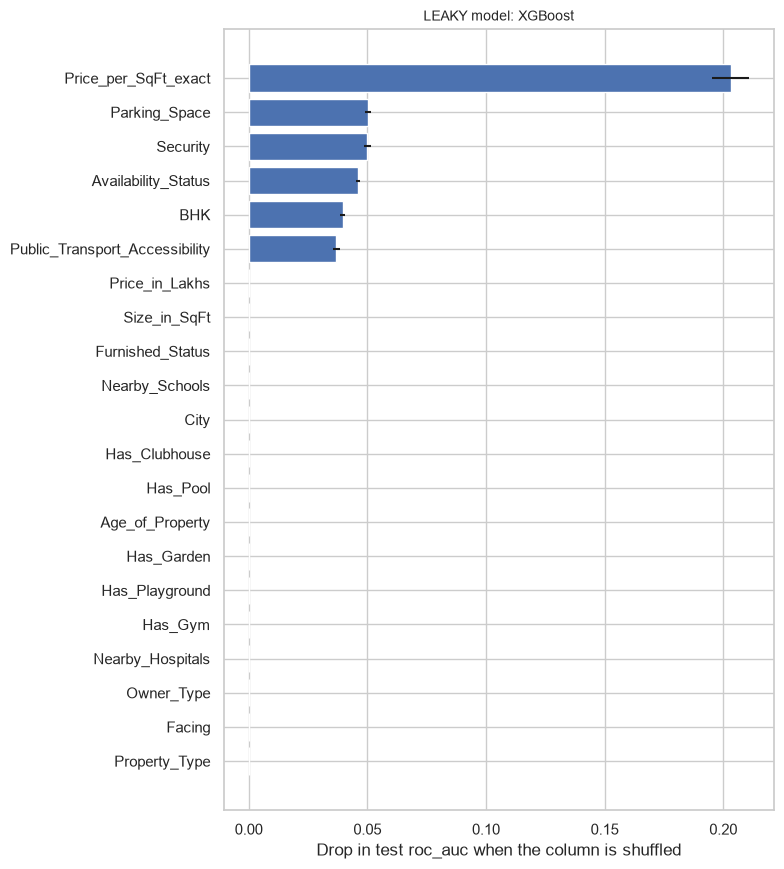

Top 5 ingredients the leaky classifier relies on:


,feature,score_drop_mean,score_drop_std
20,Price_per_SqFt_exact,0.2031,0.0077
16,Parking_Space,0.0504,0.0013
17,Security,0.0500,0.0014
15,Availability_Status,0.0461,0.0009
14,BHK,0.0396,0.0009


These are the columns that DEFINE the label (price, size, BHK, status, parking, security, transport).


In [38]:
# Leakage demonstration: which ingredients does the rule-recovery model lean on?
leaky_name = best_leaky["run_name"]
imp_leaky = permutation_table(PIPES[("cls", leaky_name)], CLS_RULE_RECOVERY_FEATURES, "roc_auc",
                              f"LEAKY model: {leaky_name.replace('CLS rule-recovery (LEAKY): ', '')}", "importance_cls_rule_recovery")
print("Top 5 ingredients the leaky classifier relies on:"); display(imp_leaky.head(5).round(4))
print("These are the columns that DEFINE the label (price, size, BHK, status, parking, security, transport).")

### PATCH 4 — is there any signal to find? (insert right after the cell that shows the "LEAKY model" importance, before Section 14)
Re-trains a fast boosted model on a sample of the training rows with the **targets randomly shuffled** several times. If the real cross-validated score is no better than the shuffled scores, the honest inputs contain no detectable information about the target — which would explain why no model can clear its threshold. The result is saved for the app.

In [39]:
# PATCH 4 - permutation (shuffled-target) signal test
from sklearn.model_selection import permutation_test_score
from sklearn.ensemble import HistGradientBoostingClassifier as _HGBC, HistGradientBoostingRegressor as _HGBR

PERM_ROWS = 10_000 if QUICK_RUN else 40_000
PERM_N = 5 if QUICK_RUN else 10
sub_idx = np.random.RandomState(SEED).choice(len(df_train), size=min(PERM_ROWS, len(df_train)), replace=False)

signal_rows = []
for task, feats, y, scoring, est, cv in (
        ("classification", CLS_FEATURES, y_train_cls, "roc_auc",
         _HGBC(max_iter=100, max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=SEED), CLS_CV),
        ("regression", REG_FEATURES, y_train_reg, "r2",
         _HGBR(max_iter=100, max_depth=4, min_samples_leaf=100, random_state=SEED), REG_CV)):
    pipe = Pipeline([("prep", build_preprocessor(feats, task)), ("model", est)])
    score, null_scores, pval = permutation_test_score(pipe, df_train[feats].iloc[sub_idx], y.iloc[sub_idx], scoring=scoring,
                                                      cv=cv, n_permutations=PERM_N, random_state=SEED, n_jobs=1)
    signal_rows.append({"task": task, "metric": f"CV {scoring}", "observed_cv_score": score, "null_mean": float(np.mean(null_scores)),
                        "null_std": float(np.std(null_scores)), "null_max": float(np.max(null_scores)), "p_value": float(pval),
                        "n_permutations": PERM_N, "sample_rows": len(sub_idx),
                        "reading": "indistinguishable from shuffled targets: no detectable signal" if pval > 0.05 else "differs from shuffled targets"})
signal_table = pd.DataFrame(signal_rows)
display(signal_table.round(4))
signal_table.to_csv(PHASE3_DIR / "signal_permutation_test.csv", index=False)
for r in signal_rows:
    print(f"{r['task'].capitalize():<15s} observed {r['observed_cv_score']:.4f} | shuffled-target scores: mean {r['null_mean']:.4f}, max {r['null_max']:.4f} | p = {r['p_value']:.3f} -> {r['reading']}")
print("\nA p-value above 0.05 means the real score cannot be told apart from scores obtained with meaningless targets.")

,task,metric,observed_cv_score,null_mean,null_std,null_max,p_value,n_permutations,sample_rows,reading
0,classification,CV roc_auc,0.5022,0.5004,0.0051,0.5084,0.4545,10,40000,indistinguishable from shuffled targets: no detectable signal
1,regression,CV r2,-0.0007,-0.0008,0.0003,-0.0002,0.3636,10,40000,indistinguishable from shuffled targets: no detectable signal


Classification  observed 0.5022 | shuffled-target scores: mean 0.5004, max 0.5084 | p = 0.455 -> indistinguishable from shuffled targets: no detectable signal
Regression      observed -0.0007 | shuffled-target scores: mean -0.0008, max -0.0002 | p = 0.364 -> indistinguishable from shuffled targets: no detectable signal

A p-value above 0.05 means the real score cannot be told apart from scores obtained with meaningless targets.


## 14. Save the final pipelines and register them in MLflow

Saved files (used by the Streamlit phase):
- `models/classifier_pipeline.joblib` and `models/regressor_pipeline.joblib` — the complete fitted pipelines (preprocessing + model);
- `models/model_metadata.json` — input columns, metrics, assumptions, label rule location, library versions and **claim limits**;
- the label rule is already saved as `phase3_outputs/label_rule.json`.

The champions are also **registered in the MLflow model registry** with the alias `champion`. A model version is tagged with whether it cleared the skill threshold.

In [40]:
def to_py(obj):
    """Make numpy numbers JSON-friendly."""
    if isinstance(obj, dict):  return {k: to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)): return [to_py(v) for v in obj]
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, (np.integer,)):  return int(obj)
    if isinstance(obj, (np.bool_,)):    return bool(obj)
    return obj

CLS_REGISTRY_NAME = "real_estate_good_investment_classifier"
REG_REGISTRY_NAME = "real_estate_future_price_scenario_regressor"

def register_champion(model_uri, name, meets_skill):
    try:
        mv = mlflow.register_model(model_uri, name)
        client = MlflowClient()
        try:
            client.set_registered_model_alias(name, "champion", mv.version)
            client.set_model_version_tag(name, mv.version, "meets_pre_declared_skill_threshold", str(meets_skill))
        except Exception as err:
            print(f"  (alias/tag step skipped for {name}: {err})")
        print(f"Registered '{name}' version {mv.version}")
        return mv.version
    except Exception as err:
        print(f"WARNING: could not register {name}: {err}")
        return None

cls_version = register_champion(champ_cls["model_uri"], CLS_REGISTRY_NAME, skill_cls)
reg_version = register_champion(champ_reg["model_uri"], REG_REGISTRY_NAME, skill_reg)

joblib.dump(pipe_cls, MODELS_DIR / "classifier_pipeline.joblib")
joblib.dump(pipe_reg, MODELS_DIR / "regressor_pipeline.joblib")

def pick(row, keys):
    return {k: row[k] for k in keys}

metadata = to_py({
    "created_session": SESSION, "quick_run": QUICK_RUN, "seed": SEED, "test_size": TEST_SIZE,
    "train_rows": len(df_train), "test_rows": len(df_test), "split_fingerprint": SPLIT_FINGERPRINT,
    "growth_rate_assumed": GROWTH_RATE, "horizon_years": HORIZON_YEARS, "growth_multiplier": GROWTH_MULTIPLIER,
    "regression_target": TARGET_REG, "classification_target": TARGET_CLS,
    "label_rule_file": "phase3_outputs/label_rule.json",
    "classification": {
        "model": champ_cls["run_name"], "input_columns": CLS_FEATURES, "mlflow_run_id": champ_cls["run_id"],
        "registered_model": CLS_REGISTRY_NAME, "registered_version": cls_version,
        "meets_pre_declared_skill_threshold": skill_cls, "skill_threshold_cv_auc": 0.5 + MIN_AUC_ABOVE_CHANCE,
        "cv": pick(champ_cls, ["cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean"]),
        "test": pick(champ_cls, ["test_accuracy", "test_balanced_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc"]),
        "baseline_test": pick(base_cls, ["test_accuracy", "test_f1", "test_roc_auc"]),
    },
    "regression": {
        "model": champ_reg["run_name"], "input_columns": REG_FEATURES, "mlflow_run_id": champ_reg["run_id"],
        "registered_model": REG_REGISTRY_NAME, "registered_version": reg_version,
        "meets_pre_declared_skill_threshold": skill_reg, "skill_threshold_cv_r2": MIN_R2,
        "cv": pick(champ_reg, ["cv_r2_mean", "cv_r2_std", "cv_rmse_mean", "cv_mae_mean"]),
        "test": pick(champ_reg, ["test_rmse", "test_mae", "test_r2", "test_rmse_over_target_std"]),
        "baseline_test": pick(base_reg, ["test_rmse", "test_mae", "test_r2"]),
    },
    "locality": {"adopted_classification": adopt_cls, "adopted_regression": adopt_reg},
    "excluded_from_inputs": {"always": NEVER_INPUTS, "classification_label_defining": LABEL_DEFINING, "regression_price_derived": PRICE_DERIVED},
    "infra_score": "descriptive only; not a model input (components used instead)",
    "library_versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                         "scikit_learn": sklearn.__version__, "mlflow": mlflow.__version__,
                         "xgboost": __import__("xgboost").__version__ if HAS_XGB else None},
    "allowed_claims": [
        "Estimates of price after 5 YEARS UNDER AN ASSUMED 8% annual growth scenario.",
        "A rule-based indicator of whether a property meets a documented value-and-quality screen.",
    ],
    "NOT_allowed_claims": [
        "Predicts actual investment returns or profitability.",
        "Forecasts verified future market prices.",
        "The 'Good Investment' label proves a property is a good buy.",
    ],
    "disclaimer": "Targets are constructed from assumptions. Scores measure how well a rule or an assumed growth rate is recovered, not real-world investment outcomes.",
})
with open(MODELS_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved: classifier_pipeline.joblib, regressor_pipeline.joblib, model_metadata.json")

# Round-trip check: reload the saved pipelines and confirm identical predictions
re_cls = joblib.load(MODELS_DIR / "classifier_pipeline.joblib"); re_reg = joblib.load(MODELS_DIR / "regressor_pipeline.joblib")
assert np.allclose(re_cls.predict_proba(df_test[CLS_FEATURES].head(500))[:, 1], proba_cls[:500])
assert np.allclose(re_reg.predict(df_test[REG_FEATURES].head(500)), pred_reg[:500])
print("PASS: reloaded pipelines reproduce the in-memory predictions.")

Registered 'real_estate_good_investment_classifier' version 2
Registered 'real_estate_future_price_scenario_regressor' version 2
Saved: classifier_pipeline.joblib, regressor_pipeline.joblib, model_metadata.json
PASS: reloaded pipelines reproduce the in-memory predictions.


Registered model 'real_estate_good_investment_classifier' already exists. Creating a new version of this model...
Created version '2' of model 'real_estate_good_investment_classifier'.
Registered model 'real_estate_future_price_scenario_regressor' already exists. Creating a new version of this model...
Created version '2' of model 'real_estate_future_price_scenario_regressor'.


### PATCH 5 — record the training environment (insert right after the Section 14 cell that saves the pipelines)
Adds the Python/library versions and the model family (XGBoost or the fallback) to `models/model_metadata.json`, so the app can show exactly what the models were trained with.

In [41]:
# PATCH 5 - record the training environment inside model_metadata.json
meta_path = MODELS_DIR / "model_metadata.json"
meta_saved = json.loads(meta_path.read_text(encoding="utf-8"))
family_text = f"{champ_cls['run_name']} {champ_reg['run_name']}"
meta_saved["environment"] = {
    "python_executable": sys.executable, "python": sys.version.split()[0], "scikit_learn": sklearn.__version__,
    "xgboost": __import__("xgboost").__version__ if HAS_XGB else None, "pandas": pd.__version__, "numpy": np.__version__,
    "required_sklearn_pin": REQUIRED_SKLEARN, "strict_environment": STRICT_ENVIRONMENT,
}
meta_saved["model_family"] = {"uses_xgboost": ("XGBoost" in family_text) and ("not installed" not in family_text),
                              "fallback_used": "XGBoost not installed" in family_text}
meta_path.write_text(json.dumps(meta_saved, indent=2), encoding="utf-8")
print("Recorded environment:", meta_saved["environment"]["scikit_learn"], "| XGBoost model family:", meta_saved["model_family"])

Recorded environment: 1.8.0 | XGBoost model family: {'uses_xgboost': False, 'fallback_used': False}


## 15. Verify the MLflow tracking

In [42]:
cls_runs = mlflow.search_runs(experiment_names=[EXP_CLS])
reg_runs = mlflow.search_runs(experiment_names=[EXP_REG])
cls_runs = cls_runs[cls_runs["tags.notebook_session"] == SESSION]
reg_runs = reg_runs[reg_runs["tags.notebook_session"] == SESSION]
print(f"Runs logged in this session -> classification: {len(cls_runs)} | regression: {len(reg_runs)}")
print("Expected:", len(CLS_RESULTS) + 2, "and", len(REG_RESULTS) + 2, "(results tables plus the 2 locality-test runs in each experiment)")
print("\nRuns by type:")
print(pd.concat([cls_runs["tags.experiment_type"].value_counts().rename("classification"),
                 reg_runs["tags.experiment_type"].value_counts().rename("regression")], axis=1).fillna(0).astype(int).to_string())
try:
    for rm in MlflowClient().search_registered_models():
        print("Registered model:", rm.name)
except Exception as err:
    print("Could not list registered models:", err)

print("\nTo browse everything in the MLflow web interface, open a terminal in the project folder and run:")
print("   mlflow ui --backend-store-uri", TRACKING_URI)
print("then open http://127.0.0.1:5000 in your browser.")

Runs logged in this session -> classification: 9 | regression: 7
Expected: 9 and 7 (results tables plus the 2 locality-test runs in each experiment)

Runs by type:
                      classification  regression
tags.experiment_type                            
rule_recovery                      3           0
primary                            3           3
locality_test                      2           2
baseline                           1           1
formula_recovery                   0           1
Registered model: real_estate_future_price_scenario_regressor
Registered model: real_estate_good_investment_classifier

To browse everything in the MLflow web interface, open a terminal in the project folder and run:
   mlflow ui --backend-store-uri sqlite:///C:/Users/Nandini/Desktop/Prime/Real-Estate-Investment-Advisor/mlflow/mlflow.db
then open http://127.0.0.1:5000 in your browser.


## 16. Summary, what the models may claim, and output check

### 16.1 Automatic summary
The text below is generated from this run's numbers, so it stays correct whatever your results are.

In [43]:
print("=" * 78)
print("PHASE 3 SUMMARY" + ("  (QUICK_RUN sample - not final)" if QUICK_RUN else ""))
print("=" * 78)
print(f"Rows: {len(df_train):,} train / {len(df_test):,} test | split fingerprint {SPLIT_FINGERPRINT}")
print(f"Locality adopted -> classification: {adopt_cls}, regression: {adopt_reg}\n")

print("CLASSIFICATION (rule-based 'Good Investment' label)")
print(f"  Champion        : {champ_cls['run_name']}")
print(f"  CV ROC AUC      : {champ_cls['cv_roc_auc_mean']:.4f} +/- {champ_cls['cv_roc_auc_std']:.4f}  (chance = 0.5; threshold {0.5 + MIN_AUC_ABOVE_CHANCE:.2f})")
print(f"  Test ROC AUC    : {champ_cls['test_roc_auc']:.4f} | F1 {champ_cls['test_f1']:.4f} | precision {champ_cls['test_precision']:.4f} | recall {champ_cls['test_recall']:.4f} | accuracy {champ_cls['test_accuracy']:.4f}")
print(f"  Baseline        : test ROC AUC {base_cls['test_roc_auc']:.4f} | accuracy {base_cls['test_accuracy']:.4f}")
print(f"  Verdict         : {'shows skill above the pre-declared threshold' if skill_cls else 'NO meaningful skill above chance using honest inputs'}")
print(f"  Leakage demo    : best leaky model test AUC {best_leaky['test_roc_auc']:.4f} (rule re-learned from its own ingredients)\n")

print("REGRESSION (5-year price under an ASSUMED 8% growth scenario)")
print(f"  Champion        : {champ_reg['run_name']}")
print(f"  CV R²           : {champ_reg['cv_r2_mean']:.4f} +/- {champ_reg['cv_r2_std']:.4f}  (threshold {MIN_R2})")
print(f"  Test            : R² {champ_reg['test_r2']:.4f} | RMSE {champ_reg['test_rmse']:.2f} | MAE {champ_reg['test_mae']:.2f} lakhs (target std {y_test_reg.std():.2f})")
print(f"  Baseline        : R² {base_reg['test_r2']:.4f} | RMSE {base_reg['test_rmse']:.2f} | MAE {base_reg['test_mae']:.2f}")
print(f"  Verdict         : {'shows skill above the pre-declared threshold' if skill_reg else 'NO meaningful skill: the honest model is no better than predicting the average'}")
print(f"  Leakage demo    : test R² {leak['test_r2']:.4f} when today's price is an input (formula recovery)")

PHASE 3 SUMMARY
Rows: 200,000 train / 50,000 test | split fingerprint 726c8219006a6c3a
Locality adopted -> classification: False, regression: False

CLASSIFICATION (rule-based 'Good Investment' label)
  Champion        : CLS primary: Logistic Regression
  CV ROC AUC      : 0.4981 +/- 0.0011  (chance = 0.5; threshold 0.52)
  Test ROC AUC    : 0.5040 | F1 0.3163 | precision 0.2358 | recall 0.4800 | accuracy 0.5114
  Baseline        : test ROC AUC 0.5000 | accuracy 0.7646
  Verdict         : NO meaningful skill above chance using honest inputs
  Leakage demo    : best leaky model test AUC 0.9997 (rule re-learned from its own ingredients)

REGRESSION (5-year price under an ASSUMED 8% growth scenario)
  Champion        : REG primary: Linear Regression
  CV R²           : -0.0005 +/- 0.0001  (threshold 0.01)
  Test            : R² -0.0004 | RMSE 207.73 | MAE 179.84 lakhs (target std 207.69)
  Baseline        : R² -0.0000 | RMSE 207.69 | MAE 179.83
  Verdict         : NO meaningful skill: the

### 16.2 What these models may and may not claim (decision 7)

| May be said | May **not** be said |
|---|---|
| "The regressor estimates the price in 5 years **if the property appreciates at an assumed 8% a year**." | "The model predicts actual investment returns." |
| "The classifier indicates whether a property meets a **documented value-and-quality rule**." | "The model proves the property is a good investment / will be profitable." |
| "Performance is reported against baselines, with the leakage demonstrations shown separately." | "The model forecasts verified future market prices." |
| "The data behaves like randomly generated data; scores say little about real markets." | Any statement based on the leakage-demonstration scores. |

When the automatic verdicts above say **no meaningful skill**, that is the finding: with the features available, honest models cannot do better than the baselines. That is a legitimate and important result for the project report — it must **not** be hidden by switching to leaky inputs or by redefining targets until the scores look good.

In [44]:
expected_files = [
    "models/classifier_pipeline.joblib", "models/regressor_pipeline.joblib", "models/model_metadata.json",
    "phase3_outputs/label_rule.json", "phase3_outputs/split_ids.csv", "phase3_outputs/locality_decision.csv",
    "phase3_outputs/classification_results.csv", "phase3_outputs/regression_results.csv",
    "phase3_outputs/test_uncertainty.csv", "phase3_outputs/floor_flag_slices.csv",
    "phase3_outputs/figures/cls_model_comparison.png", "phase3_outputs/figures/cls_confusion_matrices.png",
    "phase3_outputs/figures/reg_model_comparison.png", "phase3_outputs/figures/champion_diagnostics.png",
    "phase3_outputs/figures/importance_cls_rule_recovery.png", "mlflow/mlflow.db",
]
status = pd.DataFrame({"file": expected_files, "exists": [(PROJECT_ROOT / f).exists() for f in expected_files]})
status["size_MB"] = [round((PROJECT_ROOT / f).stat().st_size / 1024**2, 3) if (PROJECT_ROOT / f).exists() else None for f in expected_files]
display(status)
print("All expected files present:", bool(status["exists"].all()))
print("Conditional files (only when a champion shows skill): importance_cls_champion.*, importance_reg_champion.*")

,file,exists,size_MB
0,models/classifier_pipeline.joblib,True,0.005
1,models/regressor_pipeline.joblib,True,0.008
2,models/model_metadata.json,True,0.005
3,phase3_outputs/label_rule.json,True,0.006
4,phase3_outputs/split_ids.csv,True,3.184
5,phase3_outputs/locality_decision.csv,True,0.000
6,phase3_outputs/classification_results.csv,True,0.002
7,phase3_outputs/regression_results.csv,True,0.001
8,phase3_outputs/test_uncertainty.csv,True,0.001
9,phase3_outputs/floor_flag_slices.csv,True,0.000


All expected files present: True
Conditional files (only when a champion shows skill): importance_cls_champion.*, importance_reg_champion.*


---
**End of notebook.** Next phase: the Streamlit app, which loads `models/*.joblib`, `models/model_metadata.json` and `phase3_outputs/label_rule.json`, shows the assumptions and disclaimers prominently, and presents results as *scenario estimates* and *rule-based screening*, never as predictions of real returns.